# Section A: Asteroids and comets

**File:** `1_Asteroids_and_Comets/jpl_small_bodies_asteroids_comets.csv` (NASA/JPL Small-Body Database).
One row = one asteroid or comet.

This notebook grows one step at a time:
Step 1 scan → Step 2 one label at a time → Step 3 two labels together → Step 4 odd things → Step 5 checks → Step 6 explain.

`A_asteroids.py` is the source; `A_asteroids.ipynb` is the same code after running, with every table and chart.
Charts go to `charts/`, the numbers behind them to `numbers/`, and a note for each one to `LOG.md`.

## Step 1: Scan

Goal: know what is in the file before drawing anything. For every column: type, % blank, min / median / max.
Then 5 example rows, and a comparison with the README.

**Reading rules used here, and why:**
- `quotechar='"'`: a few names start with an apostrophe (`'Oumuamua`). The apostrophe must not be treated as a quote mark.
- `keep_default_na=False, na_values=[""]`: only truly empty cells count as blank. (By default pandas also turns text such as "NA" or "None" into blanks.)
- Text columns are read as text, so designations like `1` and `2017 U1` stay exactly as written.
  Every other column is forced to be a number: if any cell in a number column were not a number, reading would stop with an error.
- This scan is the one place where every column is loaded, because a scan needs every column.
  From Step 2 on, each chart loads only the columns it needs (`usecols=`).

In [1]:
import csv
import re
import sys
import time

import matplotlib
import numpy as np
import pandas as pd

import helpers as hp

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 45)
pd.set_option("display.max_rows", 60)

print("Python :", sys.executable)
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

FILE = hp.FILES["asteroids"]
print("File   :", hp.rel(FILE))
print(f"Size   : {FILE.stat().st_size:,} bytes ({FILE.stat().st_size / 1e6:.1f} MB)")

Python : /home/shaken/NASA_VIsualizations/.venv/bin/python
pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2
File   : NASA Beyond Earth-20261107T174934Z-1-001/NASA Beyond Earth/1_Asteroids_and_Comets/jpl_small_bodies_asteroids_comets.csv
Size   : 256,750,476 bytes (256.8 MB)


In [2]:
TEXT_COLS = ["full_name", "pdes", "name", "kind", "neo", "pha", "class", "first_obs", "last_obs"]

header = pd.read_csv(FILE, nrows=0).columns.tolist()
NUM_COLS = [c for c in header if c not in TEXT_COLS]
dtypes = {c: "str" for c in TEXT_COLS} | {c: "float64" for c in NUM_COLS}
dtypes["spkid"] = "int64"  # the ID: must be a whole number in every row

t0 = time.time()
ast = pd.read_csv(FILE, quotechar='"', keep_default_na=False, na_values=[""], dtype=dtypes)
print(f"Read {len(ast):,} rows x {ast.shape[1]} columns in {time.time() - t0:.1f} s")
print(f"Text columns ({len(TEXT_COLS)}):", ", ".join(TEXT_COLS))
print(f"Number columns ({len(NUM_COLS)}):", ", ".join(NUM_COLS))
print("Every number column was read as a number with no errors.")

Read 1,582,869 rows x 29 columns in 4.6 s
Text columns (9): full_name, pdes, name, kind, neo, pha, class, first_obs, last_obs
Number columns (20): spkid, H, diameter, albedo, rot_per, e, a, q, ad, i, om, w, ma, per_y, moid, moid_jup, t_jup, n_obs_used, data_arc, condition_code
Every number column was read as a number with no errors.


### 1a. Row count, compared with the README

Two independent counts: pandas rows, and raw lines in the file (no CSV parsing at all, minus 1 for the header).
The README numbers are pulled out of the README text by code, not typed in.

In [3]:
with open(FILE, "rb") as f:
    n_lines = sum(1 for _ in f)

readme = hp.README.read_text()
m = re.search(r"jpl_small_bodies_asteroids_comets\.csv` \(([\d,]+) rows, ([\d.]+) MB\)", readme)
readme_rows, readme_mb = int(m.group(1).replace(",", "")), float(m.group(2))
m = re.search(
    r"about ([\d,]+) near-Earth objects, about ([\d,]+) flagged as potentially hazardous, "
    r"and about ([\d,]+) with measured sizes",
    readme,
)
readme_neo, readme_pha, readme_size = (int(g.replace(",", "")) for g in m.groups())

# Column names listed in the README table for this file
sec = readme.split("### 1\\. Asteroids and Comets")[1].split("Extras:")[0]
readme_cols = []
for line in sec.splitlines():
    if line.startswith("| `"):
        readme_cols += re.findall(r"`([^`]+)`", line.split("|")[1])

n = len(ast)
size_mb = FILE.stat().st_size / 1e6
n_neo, n_pha, n_size = int((ast["neo"] == "Y").sum()), int((ast["pha"] == "Y").sum()), int(ast["diameter"].notna().sum())


def close(a, b, tol=0.05):
    return "yes" if abs(a - b) <= tol * b else "NO"


readme_check = pd.DataFrame(
    [
        ["Data rows (pandas)", f"{readme_rows:,}", f"{n:,}", "yes" if n == readme_rows else "NO"],
        ["Raw lines minus header", f"{readme_rows:,}", f"{n_lines - 1:,}", "yes" if n_lines - 1 == readme_rows else "NO"],
        ["File size (MB)", f"{readme_mb:g}", f"{size_mb:.1f}", close(size_mb, readme_mb, 0.01)],
        ["Columns", f"{len(readme_cols)} named in README table", f"{ast.shape[1]} in file",
         "yes, same names" if set(readme_cols) == set(ast.columns) else "NO"],
        ["Near-Earth objects (neo = Y)", f"about {readme_neo:,}", f"{n_neo:,}", close(n_neo, readme_neo)],
        ["Potentially hazardous (pha = Y)", f"about {readme_pha:,}", f"{n_pha:,}", close(n_pha, readme_pha)],
        ["Has a measured size (diameter filled)", f"about {readme_size:,}", f"{n_size:,}", close(n_size, readme_size)],
    ],
    columns=["What", "README says", "File has", "Match?"],
)
print("Columns in file but not in README:", sorted(set(ast.columns) - set(readme_cols)) or "none")
print("Columns in README but not in file:", sorted(set(readme_cols) - set(ast.columns)) or "none")
readme_check

Columns in file but not in README: none
Columns in README but not in file: none


,What,README says,File has,Match?
0,Data rows (pandas),"1,582,869","1,582,869",yes
1,Raw lines minus header,"1,582,869","1,582,869",yes
2,File size (MB),257,256.8,yes
3,Columns,29 named in README table,29 in file,"yes, same names"
4,Near-Earth objects (neo = Y),"about 43,000","43,050",yes
5,Potentially hazardous (pha = Y),"about 2,500","2,550",yes
6,Has a measured size (diameter filled),"about 140,000","139,688",yes


### 1b. Every column: type, % blank, min / median / max

"Blank" = empty cell. For number columns: min / median / max of the filled cells.
For text columns: how many different values, and the most common ones.

In [4]:
def kind_of(s):
    if s.dtype == "str" or s.dtype == object:
        return "text"
    filled = s.dropna()
    return "number (whole)" if np.all(np.mod(filled, 1) == 0) else "number (decimal)"


rows = []
for col in ast.columns:
    s = ast[col]
    blank = int(s.isna().sum())
    r = {
        "column": col,
        "type": kind_of(s),
        "filled": n - blank,
        "blank": blank,
        "pct_blank": 100 * blank / n,
        "n_different": int(s.nunique(dropna=True)),
    }
    if r["type"] != "text":
        r |= {"min": s.min(), "median": s.median(), "max": s.max()}
    else:
        if r["n_different"] == r["filled"]:
            r["most_common"] = "every value is different"
        else:
            top = s.value_counts().head(3)
            r["most_common"] = "; ".join(f"{k} ({v:,})" for k, v in top.items())
    rows.append(r)
scan = pd.DataFrame(rows)


def nice(x):
    if pd.isna(x):
        return ""
    x = float(x)
    if x.is_integer() and abs(x) < 1e12:
        return f"{int(x):,}"
    if abs(x) >= 1e6 or (0 < abs(x) < 1e-3):
        return f"{x:.4g}"
    return f"{x:,.6g}"


show = scan.copy()
show["pct_blank"] = show["pct_blank"].map(lambda x: f"{x:.1f}%")
for c in ["filled", "blank", "n_different"]:
    show[c] = show[c].map("{:,}".format)
for c in ["min", "median", "max"]:
    show[c] = show[c].map(nice)
show = show.fillna("")
show

,column,type,filled,blank,pct_blank,n_different,min,median,max,most_common
0,spkid,number (whole),"1,582,869",0,0.0%,"1,582,869","1,000,001","20,787,352","54,668,917",
1,full_name,text,"1,582,869",0,0.0%,"1,582,869",,,,every value is different
2,pdes,text,"1,582,869",0,0.0%,"1,582,869",,,,every value is different
3,name,text,"30,576","1,552,293",98.1%,"27,009",,,,"SOHO (1,465); PANSTARRS (354); LINEAR (205)"
4,kind,text,"1,582,869",0,0.0%,4,,,,"an (895,910); au (682,876); cu (3,473)"
5,neo,text,"1,578,990","3,879",0.2%,2,,,,"N (1,535,940); Y (43,050)"
6,pha,text,"1,520,750","62,119",3.9%,2,,,,"N (1,518,200); Y (2,550)"
7,class,text,"1,582,869",0,0.0%,21,,,,"MBA (1,395,259); OMB (50,991); IMB (33,150)"
8,H,number (decimal),"1,578,278","4,591",0.3%,"2,739",-1.26,17.66,34.06,
9,diameter,number (decimal),"139,688","1,443,181",91.2%,"16,790",0.0025,3.95,939.4,


**Chart A00a: blank cells in each column.** The blank counts from the table, as a picture.
They run from 25 to over 1.5 million (many powers of ten), so the axis is log scale.

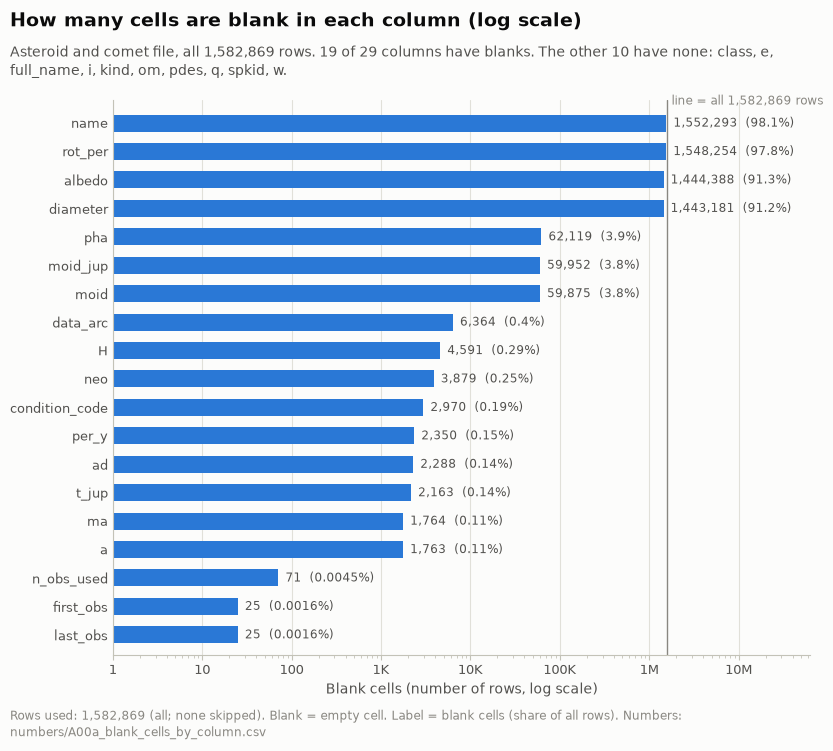

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

hp.chart_style()

order = scan.sort_values(["blank", "column"], ascending=[False, True])
with_blanks = order[order["blank"] > 0]
no_blanks = order.loc[order["blank"] == 0, "column"].tolist()


def pct_label(p):
    return f"{p:.1f}%" if p >= 1 else f"{p:.2g}%"


fig, ax = plt.subplots(figsize=(9, 7.2))
yy = np.arange(len(with_blanks))[::-1]  # most blank at the top
ax.barh(yy, with_blanks["blank"], height=0.6, color=hp.SERIES[0])
for yi, v, p in zip(yy, with_blanks["blank"], with_blanks["pct_blank"]):
    ax.text(v * 1.2, yi, f"{v:,}  ({pct_label(p)})", va="center", ha="left", fontsize=8.5, color=hp.INK_2)
ax.axvline(n, color=hp.INK_MUTED, lw=1)
ax.text(n * 1.12, len(with_blanks) - 0.45, f"line = all {n:,} rows", va="bottom", ha="left", fontsize=8.5,
        color=hp.INK_MUTED)
ax.set_xscale("log")
ax.set_xlim(1, n * 40)
ax.set_ylim(-0.7, len(with_blanks) - 0.2)
ax.xaxis.set_major_formatter(FuncFormatter(hp.compact))
ax.set_yticks(yy, with_blanks["column"])
ax.set_xlabel("Blank cells (number of rows, log scale)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
hp.add_titles(
    fig,
    "How many cells are blank in each column (log scale)",
    f"Asteroid and comet file, all {n:,} rows. {len(with_blanks)} of {len(scan)} columns have blanks. "
    f"The other {len(no_blanks)} have none: {', '.join(no_blanks)}.",
    f"Rows used: {n:,} (all; none skipped). Blank = empty cell. Label = blank cells (share of all rows). "
    "Numbers: numbers/A00a_blank_cells_by_column.csv",
)
chart_a = hp.save_chart(fig, "A00a_blank_cells_by_column")
plt.show()

nums_a = hp.save_numbers(order[["column", "type", "filled", "blank", "pct_blank"]], "A00a_blank_cells_by_column")
big = with_blanks[with_blanks["pct_blank"] > 50]
rest = with_blanks[with_blanks["pct_blank"] <= 50]
hp.log_entry(
    "A00a",
    "Bar chart: blank cells in each column (log scale)",
    step=1,
    chart=chart_a,
    numbers=nums_a,
    rows_used=n,
    rows_skipped=0,
    key_numbers=[
        f"{len(with_blanks)} of {len(scan)} columns have blanks; {len(no_blanks)} have none",
        "more than half blank: " + ", ".join(f"{r.column} {r.blank:,} ({r.pct_blank:.1f}%)" for r in big.itertuples()),
        f"all other columns: at most {rest['pct_blank'].max():.1f}% blank ({rest.iloc[0].column})",
        f"fewest blanks (but not zero): {with_blanks.iloc[-1].column} with {with_blanks.iloc[-1].blank:,}",
    ],
    what_it_shows=(
        f"{len(big)} columns are mostly empty ({', '.join(big['column'])}); every other column is at least "
        f"{100 - rest['pct_blank'].max():.1f}% filled."
    ),
)

### 1c. The two date columns

`first_obs` and `last_obs` are text, not real dates: some are partial (`1999-??-??`) and a few years are negative (`-146`).
The year is the text before the first dash; a leading minus sign is kept, so `-146-08-06` gives year −146.

In [6]:
date_rows = []
years = {}
for col in ["first_obs", "last_obs"]:
    s = ast[col]
    year = pd.to_numeric(s.str.extract(r"^(-?\d+)-", expand=False), errors="coerce")
    years[col] = year
    date_rows.append({
        "column": col,
        "filled": int(s.notna().sum()),
        "blank": int(s.isna().sum()),
        "full date (YYYY-MM-DD)": int(s.str.fullmatch(r"\d{4}-\d{2}-\d{2}").fillna(False).sum()),
        "partial (has ??)": int(s.str.contains("??", regex=False).fillna(False).sum()),
        "year has < 4 digits": int((year.abs() < 1000).sum()),
        "negative year": int((year < 0).sum()),
        "filled but no year found": int((s.notna() & year.isna()).sum()),
        "min year": int(year.min()),
        "median year": float(year.median()),
        "max year": int(year.max()),
    })
dates = pd.DataFrame(date_rows).set_index("column").T
print(f"Rows where last_obs year is before first_obs year: {int((years['last_obs'] < years['first_obs']).sum()):,}")
dates

Rows where last_obs year is before first_obs year: 0


column,first_obs,last_obs
filled,1582844.0,1582844.0
blank,25.0,25.0
full date (YYYY-MM-DD),1576999.0,1582824.0
partial (has ??),5829.0,4.0
year has < 4 digits,16.0,16.0
negative year,2.0,2.0
filled but no year found,0.0,0.0
min year,-146.0,-146.0
median year,2007.0,2025.0
max year,2026.0,2026.0


In [7]:
# The rows with very old years (fewer than 4 digits, or negative)
old = ast.loc[years["first_obs"].abs() < 1000, ["full_name", "kind", "class", "first_obs", "last_obs", "n_obs_used"]]
old.assign(first_year=years["first_obs"][old.index].astype(int)).sort_values("first_year")

,full_name,kind,class,first_obs,last_obs,n_obs_used,first_year
1579396,C/-146 P1,cu,PAR,-146-08-06,-146-08-11,4.0,-146
1579397,C/-43 K1,cu,PAR,-43-05-30,-43-07-23,NaN,-43
1579398,C/240 V1,cu,PAR,240-11-10,240-12-19,NaN,240
1579399,C/390 Q1,cu,PAR,390-08-22,390-09-17,3.0,390
1579400,C/400 F1,cu,PAR,400-03-19,400-04-10,NaN,400
1579401,C/418 M1,cu,PAR,418-06-24,418-09-14,NaN,418
1579402,C/442 V1,cu,PAR,442-11-10,443-02-18,NaN,442
1579403,C/539 W1,cu,PAR,539-11-17,540-01-30,NaN,539
1579404,C/565 O1,cu,PAR,565-07-22,565-11-04,NaN,565
1579405,C/568 O1,cu,PAR,568-09-03,568-11-05,4.0,568


### 1d. The category columns: what values appear, and where the blanks are

In [8]:
for col in ["kind", "neo", "pha"]:
    vc = ast[col].fillna("(blank)").value_counts()
    print(f"{col:5s}:", " | ".join(f"{k} = {v:,}" for k, v in vc.items()), f" (total {vc.sum():,})")
print(f"class: {ast['class'].nunique()} different codes, {int(ast['class'].isna().sum())} blank")
cc = ast["condition_code"].value_counts(dropna=False).sort_index()
print("condition_code:", " | ".join(f"{('blank' if pd.isna(k) else int(k))} = {v:,}" for k, v in cc.items()))
print()
print("Blanks in neo, pha, H and moid, by kind (an = numbered asteroid, au = unnumbered asteroid, cn / cu = comet):")
blanks_by_kind = pd.concat(
    {
        "rows": ast["kind"].value_counts(),
        "neo blank": ast.loc[ast["neo"].isna(), "kind"].value_counts(),
        "pha blank": ast.loc[ast["pha"].isna(), "kind"].value_counts(),
        "H blank": ast.loc[ast["H"].isna(), "kind"].value_counts(),
        "moid blank": ast.loc[ast["moid"].isna(), "kind"].value_counts(),
    },
    axis=1,
).fillna(0).astype(int).reindex(["an", "au", "cn", "cu"])
blanks_by_kind

kind : an = 895,910 | au = 682,876 | cu = 3,473 | cn = 610  (total 1,582,869)
neo  : N = 1,535,940 | Y = 43,050 | (blank) = 3,879  (total 1,582,869)


pha  : N = 1,518,200 | (blank) = 62,119 | Y = 2,550  (total 1,582,869)
class: 21 different codes, 0 blank
condition_code: 0 = 1,142,079 | 1 = 97,105 | 2 = 60,038 | 3 = 23,379 | 4 = 26,784 | 5 = 37,723 | 6 = 37,057 | 7 = 43,644 | 8 = 49,941 | 9 = 62,149 | blank = 2,970

Blanks in neo, pha, H and moid, by kind (an = numbered asteroid, au = unnumbered asteroid, cn / cu = comet):


,rows,neo blank,pha blank,H blank,moid blank
kind,,,,,
an,895910,0,0,0,0
au,682876,5,58036,509,58036
cn,610,448,610,610,2
cu,3473,3426,3473,3472,1837


In [9]:
# Which asteroids (not comets) have a blank neo flag?
print("Asteroids (kind an/au) with neo blank:")
print(ast.loc[ast["kind"].isin(["an", "au"]) & ast["neo"].isna(), ["full_name", "kind", "class", "e", "a", "q", "H"]].to_string())
print()
# Does a blank pha go with a blank moid? (rows = pha blank or not, columns = moid blank or not)
print("Asteroids only: pha blank? (rows) against moid blank? (columns)")
asts = ast[ast["kind"].isin(["an", "au"])]
pd.crosstab(asts["pha"].isna().map({True: "pha blank", False: "pha filled"}),
            asts["moid"].isna().map({True: "moid blank", False: "moid filled"}), margins=True)

Asteroids (kind an/au) with neo blank:
                     full_name kind class       e          a      q      H
954356          (A/2010 LN135)   au   HYA  1.0008  -2082.000  1.741  14.05
1220009  'Oumuamua (A/2017 U1)   au   HYA  1.2011     -1.272  0.256  22.08
1438481            (A/2023 R3)   au   HYA  1.0001 -15680.000  1.358  19.96
1474622            (A/2024 U2)   au   HYA  1.0027  -3068.000  8.179  11.34
1476593            (A/2024 W2)   au   HYA  1.0024  -1538.000  3.721  15.56

Asteroids only: pha blank? (rows) against moid blank? (columns)


moid,moid blank,moid filled,All
pha,,,
pha blank,58036,0,58036
pha filled,0,1520750,1520750
All,58036,1520750,1578786


In [10]:
# What do the four kind codes look like? (The README says: an = numbered asteroid, au = unnumbered asteroid,
# cn / cu = comet.) Three example names of each, and the first rows of each kind:
for k in ["an", "au", "cn", "cu"]:
    s = ast.loc[ast["kind"] == k, "full_name"]
    print(f"{k}: {len(s):>7,} rows | e.g. {' | '.join(s.sample(3, random_state=1))}")
print("cn designations that are a number + P/D/I (like 1P = Halley):",
      int(ast.loc[ast["kind"] == "cn", "pdes"].str.match(r"^\d+[PDI]").sum()), "of", int((ast["kind"] == "cn").sum()))

an: 895,910 rows | e.g. 30125 Mikekiser (2000 FF41) | 732260 (2014 BB83) | 344747 (2003 UA277)
au: 682,876 rows | e.g. (2025 ON576) | (2016 EK223) | (2015 HS236)
cn:     610 rows | e.g. 50P/Arend | 156P/Russell-LINEAR | 119P/Parker-Hartley
cu:   3,473 rows | e.g. C/1924 F1 (Reid) | C/1859 G1 (Tempel) | C/2002 T7 (LINEAR)
cn designations that are a number + P/D/I (like 1P = Halley): 610 of 610


**Chart A00b: where the blanks are, by kind of object.** Same blank cells, split by `kind`.
Each cell is the % of that kind's rows where the column is empty (darker = more blank).

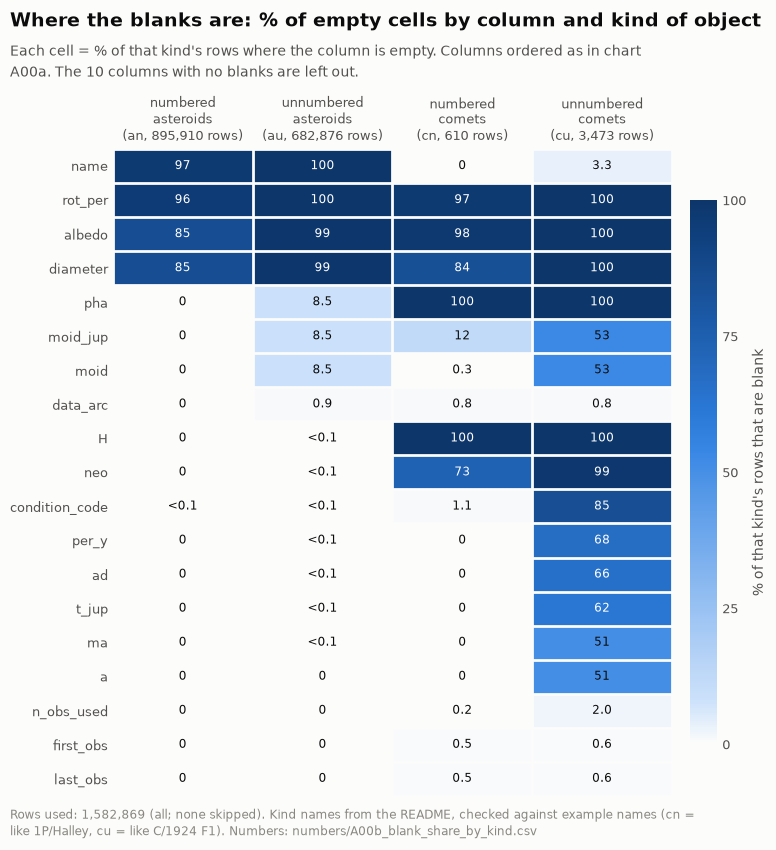

In [11]:
kinds = ["an", "au", "cn", "cu"]
kind_label = {"an": "numbered\nasteroids", "au": "unnumbered\nasteroids", "cn": "numbered\ncomets", "cu": "unnumbered\ncomets"}
cols_b = with_blanks["column"].tolist()  # same order as chart A00a: most blank first
kind_n = ast["kind"].value_counts()
share = pd.DataFrame({k: ast.loc[ast["kind"] == k, cols_b].isna().mean() * 100 for k in kinds})


def cell_text(v):
    if v == 0:
        return "0"
    if v < 0.1:
        return "<0.1"
    return f"{v:.1f}" if v < 10 else f"{v:.0f}"


fig, ax = plt.subplots(figsize=(7.8, 8.4))
im = ax.imshow(share.values, cmap=hp.seq_cmap(), vmin=0, vmax=100, aspect="auto")
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        ax.text(j, i, cell_text(v), ha="center", va="center", fontsize=8.5,
                color="white" if v > 55 else hp.INK)
ax.set_xticks(range(len(kinds)), [f"{kind_label[k]}\n({k}, {kind_n[k]:,} rows)" for k in kinds])
ax.set_yticks(range(len(cols_b)), cols_b)
ax.xaxis.tick_top()
ax.set_xticks(np.arange(-0.5, len(kinds)), minor=True)
ax.set_yticks(np.arange(-0.5, len(cols_b)), minor=True)
ax.grid(which="major", visible=False)
ax.grid(which="minor", color=hp.SURFACE, linewidth=2)  # 2px gap between cells
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03, ticks=[0, 25, 50, 75, 100])
cb.set_label("% of that kind's rows that are blank")
cb.outline.set_visible(False)
cb.ax.tick_params(length=0)
hp.add_titles(
    fig,
    "Where the blanks are: % of empty cells by column and kind of object",
    f"Each cell = % of that kind's rows where the column is empty. Columns ordered as in chart A00a. "
    f"The {len(no_blanks)} columns with no blanks are left out.",
    f"Rows used: {n:,} (all; none skipped). Kind names from the README, checked against example names "
    "(cn = like 1P/Halley, cu = like C/1924 F1). Numbers: numbers/A00b_blank_share_by_kind.csv",
)
chart_b = hp.save_chart(fig, "A00b_blank_share_by_kind")
plt.show()

table_b = share.round(4).rename_axis("column").reset_index()
table_b.columns = ["column"] + [f"pct_blank_{k}" for k in kinds]
nums_b = hp.save_numbers(table_b, "A00b_blank_share_by_kind")

# Facts for the log, each one checked by code so the sentence can't drift from the numbers
an_clean = [c for c in cols_b if share.loc[c, "an"] == 0]
comet_full = [c for c in cols_b if share.loc[c, "cn"] == 100 and share.loc[c, "cu"] > 99.9]
hp.log_entry(
    "A00b",
    "Heatmap: % blank by column and kind of object",
    step=1,
    chart=chart_b,
    numbers=nums_b,
    rows_used=n,
    rows_skipped=0,
    key_numbers=[
        "rows per kind: " + ", ".join(f"{k} {kind_n[k]:,}" for k in kinds),
        f"numbered asteroids (an) have no blanks in: {', '.join(an_clean)}",
        f"comets are (almost) entirely blank in: {', '.join(comet_full)}",
        f"moid blank: an {share.loc['moid', 'an']:.1f}%, au {share.loc['moid', 'au']:.1f}%, "
        f"cn {share.loc['moid', 'cn']:.1f}%, cu {share.loc['moid', 'cu']:.1f}%",
        f"diameter blank: an {share.loc['diameter', 'an']:.1f}%, au {share.loc['diameter', 'au']:.1f}%",
    ],
    what_it_shows=(
        f"Blanks are not spread evenly: comets are blank in {' and '.join(comet_full)}; numbered asteroids are "
        f"complete in {len(an_clean)} of the {len(cols_b)} columns that have blanks elsewhere; and unnumbered "
        f"asteroids are blank in moid and pha for {share.loc['moid', 'au']:.1f}% of rows."
    ),
)

### 1e. Known traps: are they really there?

The brief lists traps that are "already known". Here they are tested on this file, not assumed.

In [12]:
e, a, per_y, ma = ast["e"], ast["a"], ast["per_y"], ast["ma"]
trap_rows = [
    ["rows with e >= 1 (orbit is open, not a closed loop)", int((e >= 1).sum())],
    ["  ... of those, a is negative", int(((e >= 1) & (a < 0)).sum())],
    ["  ... of those, a is blank", int(((e >= 1) & a.isna()).sum())],
    ["  ... of those, a is positive", int(((e >= 1) & (a > 0)).sum())],
    ["  ... of those, per_y is blank", int(((e >= 1) & per_y.isna()).sum())],
    ["rows with e < 1", int((e < 1).sum())],
    ["  ... of those, a is negative", int(((e < 1) & (a < 0)).sum())],
    ["  ... of those, per_y is blank", int(((e < 1) & per_y.isna()).sum())],
    ["rows with e blank", int(e.isna().sum())],
    ["all rows with a < 0", int((a < 0).sum())],
    ["all rows with a blank", int(a.isna().sum())],
    ["all rows with per_y blank", int(per_y.isna().sum())],
    ["ma below 0", int((ma < 0).sum())],
    ["ma exactly 360", int((ma == 360).sum())],
    ["ma above 360", int((ma > 360).sum())],
]
traps = pd.DataFrame(trap_rows, columns=["check", "rows"])
traps["rows"] = traps["rows"].map("{:,}".format)
print(traps.to_string(index=False))

                                              check      rows
rows with e >= 1 (orbit is open, not a closed loop)     2,313
                        ... of those, a is negative       525
                           ... of those, a is blank     1,763
                        ... of those, a is positive        25
                       ... of those, per_y is blank     2,289
                                    rows with e < 1 1,580,556
                        ... of those, a is negative         0
                       ... of those, per_y is blank        61
                                  rows with e blank         0
                                all rows with a < 0       525
                              all rows with a blank     1,763
                          all rows with per_y blank     2,350
                                         ma below 0        46
                                     ma exactly 360       242
                                       ma above 360         1


In [13]:
# e is written with 4 decimals, so "e = 1" in the file can hide values a little above or below 1.
# Split the e >= 1 rows by the exact value of e, the sign of a, and the orbit class.
grp = np.select([e > 1, e == 1], ["e > 1", "e = 1 (as written)"], "e < 1")
a_sign = np.select([a < 0, a > 0, a.isna()], ["a negative", "a positive", "a blank"], "a = 0")
open_rows = e >= 1
print("Rows with e >= 1, by e, sign of a, and class:")
print(pd.crosstab([pd.Series(grp[open_rows], name="e"), pd.Series(a_sign[open_rows], name="a")],
                  pd.Series(ast.loc[open_rows, "class"].values, name="class")).to_string())
print()
x = ast[(e < 1) & per_y.isna()]
print(f"Rows with e < 1 but per_y blank: {len(x)}; class: {x['class'].value_counts().to_dict()}; "
      f"e from {x['e'].min()} to {x['e'].max()}; a from {x['a'].min():,} to {x['a'].max():,} AU")
print()
print("The ma value above 360:")
print(ast.loc[ma > 360, ["full_name", "kind", "class", "e", "a", "ma"]].to_string())
print()
print("Names that start with an apostrophe (should look normal if the reader handled them):")
ast.loc[ast["name"].str.startswith("'").fillna(False), ["spkid", "full_name", "pdes", "name", "kind", "class", "e"]]

Rows with e >= 1, by e, sign of a, and class:
class                          COM  HYA  HYP   PAR
e                  a                              
e = 1 (as written) a blank       0    0    0  1763
                   a negative    0    0   32     0
                   a positive   25    0    0     0
e > 1              a negative    0    5  488     0

Rows with e < 1 but per_y blank: 61; class: {'COM': 61}; e from 0.9837 to 0.9999; a from 99.97 to 12,390.0 AU

The ma value above 360:
                 full_name kind class       e       a       ma
1582820  C/2025 N1 (ATLAS)   cu   HYP  6.1235 -0.2639  2636.11

Names that start with an apostrophe (should look normal if the reader handled them):


,spkid,full_name,pdes,name,kind,class,e
388281,20388282,388282 'Akepa (2006 RC118),388282,'Akepa,an,MBA,0.1321
594912,20594913,594913 'Aylo'chaxnim (2020 AV2),594913,'Aylo'chaxnim,an,IEO,0.1773
1220009,50788063,'Oumuamua (A/2017 U1),2017 U1,'Oumuamua,au,HYA,1.2011


### 1f. Five example rows

A random 5 (fixed seed, so the same 5 come back every run), shown sideways so all 29 columns fit.

In [14]:
examples = ast.sample(5, random_state=2026)
examples.T

,1366064,131877,44628,236987,561699
spkid,54200282,20131878,20044629,20236988,20561700
full_name,(2021 QL45),131878 (2002 AY163),44629 (1999 RT83),236988 Robberto (2008 QE12),561700 (2015 UZ47)
pdes,2021 QL45,131878,44629,236988,561700
name,NaN,NaN,NaN,Robberto,NaN
kind,au,an,an,an,an
neo,N,N,N,N,N
pha,N,N,N,N,N
class,MBA,MBA,MBA,MBA,MBA
H,17.38,16.67,15.47,17.57,18.3
diameter,NaN,NaN,NaN,NaN,NaN


### 1g. Second count of the blanks, without pandas

The blank counts above come from pandas. Here Python's plain `csv` module re-reads the raw file and counts
empty cells per column. If both methods agree, the blanks are real and not a side effect of how pandas reads the file.

In [15]:
t0 = time.time()
with open(FILE, newline="") as f:
    reader = csv.reader(f, quotechar='"')
    hdr = next(reader)
    blank_counts = [0] * len(hdr)
    n_rows = bad_len = 0
    for row in reader:
        n_rows += 1
        if len(row) != len(hdr):
            bad_len += 1
            continue
        for j, v in enumerate(row):
            if v == "":
                blank_counts[j] += 1
csv_blanks = pd.Series(blank_counts, index=hdr)
diff = csv_blanks - scan.set_index("column")["blank"]
print(f"csv module: {n_rows:,} rows, {bad_len} rows with the wrong number of fields ({time.time() - t0:.1f} s)")
print("Columns where the two blank counts differ:", list(diff[diff != 0].index) or "none, all 29 match")

csv module: 1,582,869 rows, 0 rows with the wrong number of fields (9.3 s)
Columns where the two blank counts differ: none, all 29 match


### 1h. Extra checks from a second, independent pass

A separate check (plain Python and awk, no pandas, run in the background) re-counted every number in this scan
and agreed with all of them. It also turned up a few traps worth knowing before Step 2. Each one is re-checked here.

In [16]:
# 1) What the apostrophe trap would have done: re-read the raw file with the apostrophe as the quote character
csv.field_size_limit(sys.maxsize)
with open(FILE, newline="") as f:
    rows_wrong_quote = sum(1 for _ in csv.reader(f, quotechar="'")) - 1
print(f"1) Apostrophe as quote character: {rows_wrong_quote:,} rows instead of {n:,} "
      f"({n - rows_wrong_quote:,} rows silently swallowed, no error)")

# 2) Orbit class codes that differ only by upper/lower case
cls = ast["class"].value_counts()
case_pairs = cls[cls.index.str.upper().duplicated(keep=False)]
print("2) class codes that differ only by upper/lower case:", case_pairs.to_dict())

# 3) pdes looks like a whole number at the top of the file, and like text further down
digits = ast["pdes"].str.fullmatch(r"\d+").to_numpy()
first_text = int(np.argmax(~digits))
print(f"3) pdes is digits only in the first {first_text:,} rows (all kind an: {bool((ast['kind'].iloc[:first_text] == 'an').all())}), "
      f"then text like '{ast['pdes'].iat[first_text]}'. A reader that guesses types from the first rows would call it a number.")

# 4) Very old dates: pandas' standard date type (nanoseconds) only reaches back to 1677
before_1678 = years["first_obs"] < 1678
print(f"4) first_obs before the year 1678: {int(before_1678.sum())} rows, kinds: {ast.loc[before_1678, 'kind'].value_counts().to_dict()}")

# 5) data_arc is a formula of two other columns: days from first_obs to last_obs
full = (ast["first_obs"].str.fullmatch(r"-?\d+-\d{2}-\d{2}").fillna(False)
        & ast["last_obs"].str.fullmatch(r"-?\d+-\d{2}-\d{2}").fillna(False)
        & ast["data_arc"].notna() & (years["first_obs"] >= 1000))
d_first = ast.loc[full, "first_obs"].to_numpy(dtype=str).astype("datetime64[D]")
d_last = ast.loc[full, "last_obs"].to_numpy(dtype=str).astype("datetime64[D]")
same_days = int(((d_last - d_first).astype(int) == ast.loc[full, "data_arc"].to_numpy()).sum())
print(f"5) data_arc = last_obs - first_obs (days) in {same_days:,} of {int(full.sum()):,} rows with two full dates and a data_arc")

# 6) Comets and the neo flag
print("6) neo values for comets (cn, cu):", ast.loc[ast["kind"].isin(["cn", "cu"]), "neo"].fillna("(blank)").value_counts().to_dict())

# 7) Columns that are formulas of other columns (orbits with e < 1)
ok = (e < 1) & a.notna() & per_y.notna()
rel_p = ((per_y[ok] - a[ok] ** 1.5).abs() / per_y[ok]).max()
ok_q = (e < 1) & a.notna() & (a < 100)
rel_q = ((ast.loc[ok_q, "q"] - a[ok_q] * (1 - e[ok_q])).abs() / ast.loc[ok_q, "q"])
print(f"7) per_y vs a**1.5: largest gap {rel_p * 100:.2f}% over {int(ok.sum()):,} rows. "
      f"q vs a*(1-e) for a < 100 AU: within 1% in {int((rel_q <= 0.01).sum()):,} of {int(ok_q.sum()):,} rows")

1) Apostrophe as quote character: 1,379,388 rows instead of 1,582,869 (203,481 rows silently swallowed, no error)
2) class codes that differ only by upper/lower case: {'JFc': 832, 'JFC': 17}
3) pdes is digits only in the first 895,910 rows (all kind an: True), then text like '1927 LA'. A reader that guesses types from the first rows would call it a number.
4) first_obs before the year 1678: 78 rows, kinds: {'cu': 78}


5) data_arc = last_obs - first_obs (days) in 1,576,489 of 1,576,489 rows with two full dates and a data_arc
6) neo values for comets (cn, cu): {'(blank)': 3874, 'Y': 209}
7) per_y vs a**1.5: largest gap 0.55% over 1,580,495 rows. q vs a*(1-e) for a < 100 AU: within 1% in 1,579,511 of 1,579,521 rows


### 1i. Save the numbers and write the LOG entry

In [17]:
files = [
    hp.save_numbers(scan, "A00_scan_columns"),
    hp.save_numbers(readme_check, "A00_readme_check"),
    hp.save_numbers(dates.T.reset_index(), "A00_dates"),
    hp.save_numbers(examples, "A00_example_rows"),
]
top_blank = scan.sort_values("pct_blank", ascending=False).head(4)
none_blank = scan.loc[scan["blank"] == 0, "column"].tolist()
d = dates.T
hp.log_entry(
    "A00",
    "Scan of the asteroid file (Step 1)",
    step=1,
                                                                                                                                                                                                                                                                                                                                                                                                                                        chart=None,
    numbers=files,
    rows_used=f"{n:,} rows x {ast.shape[1]} columns (all columns, scan only)",
    rows_skipped="0 rows dropped; blanks are counted per column (see numbers file)",
    key_numbers=[
        f"rows: {n:,} (pandas) = {n_lines - 1:,} (raw lines minus header) = {readme_rows:,} (README)",
        f"neo = Y: {n_neo:,} | pha = Y: {n_pha:,} | diameter filled: {n_size:,}",
        "most blank: " + ", ".join(f"{r.column} {r.pct_blank:.1f}%" for r in top_blank.itertuples()),
        f"columns with no blanks: {len(none_blank)} ({', '.join(none_blank)})",
        f"e >= 1: {int((e >= 1).sum()):,} rows; a < 0: {int((a < 0).sum()):,}; a blank: {int(a.isna().sum()):,}; "
        f"per_y blank: {int(per_y.isna().sum()):,}",
        f"e < 1 but per_y blank: {len(x)} rows (class {', '.join(f'{k} {v}' for k, v in x['class'].value_counts().items())}; "
        f"e {x['e'].min()} to {x['e'].max()})",
        f"ma outside 0-360: {int((ma < 0).sum())} below 0, {int((ma == 360).sum())} exactly 360, {int((ma > 360).sum())} above 360",
        f"asteroids with neo blank: {int((ast['kind'].isin(['an', 'au']) & ast['neo'].isna()).sum())}; "
        f"asteroids with pha blank: {int((ast['kind'].isin(['an', 'au']) & ast['pha'].isna()).sum()):,}",
        f"first_obs: {int(d.loc['first_obs', 'partial (has ??)']):,} partial dates, "
        f"{int(d.loc['first_obs', 'negative year'])} negative years, year range "
        f"{int(d.loc['first_obs', 'min year'])} to {int(d.loc['first_obs', 'max year'])}",
        f"blank counts: pandas and plain csv module agree on {int((diff == 0).sum())} of {len(diff)} columns",
        f"apostrophe used as quote character by mistake: {rows_wrong_quote:,} rows instead of {n:,}",
        f"class codes that differ only by case: {case_pairs.to_dict()}",
        f"first_obs before 1678: {int(before_1678.sum())} rows; data_arc = last_obs - first_obs in "
        f"{same_days:,} of {int(full.sum()):,} rows",
    ],
    what_it_shows=(
        f"Every row was read: pandas, the raw line count and the README all give {n:,}. "
        "The emptiest columns are "
        + ", ".join(f"{r.column} ({r.pct_blank:.1f}% blank)" for r in top_blank.itertuples())
        + f"; {len(none_blank)} columns have no blanks at all."
    ),
)
print("Saved:", *files, sep="\n  ")
hp.progress("A", 1)
print("LOG.md updated (entry A00, Step 1 marked done).")

Saved:
  numbers/A00_scan_columns.csv
  numbers/A00_readme_check.csv
  numbers/A00_dates.csv
  numbers/A00_example_rows.csv
LOG.md updated (entry A00, Step 1 marked done).


## Step 2: One label at a time

One chart per column (or small group of columns): histograms for number columns, bar charts for category columns.
Every chart says how many rows it used and how many it skipped (blank, or outside the chart's range).
From here on the file is read with only the columns the charts need (`usecols=`), through `hp.read_csv`,
which applies the same reading rules as Step 1.

In [18]:
hp.tick("before freeing Step 1")
del ast, asts, e, a, per_y, ma, x, old, full, d_first, d_last, digits  # free the full table and its copies
import gc; gc.collect()
hp.tick("after freeing Step 1")
COLS2 = ["kind", "class", "H", "e", "i", "a", "diameter", "albedo", "rot_per", "condition_code"]
d2 = hp.read_csv("asteroids", usecols=COLS2)
hp.tick("Step 2 columns read")
same_blanks = bool((d2.isna().sum().values == scan.set_index("column").loc[COLS2, "blank"].values).all())
print(f"{len(d2):,} rows x {d2.shape[1]} columns. Blank counts match the Step 1 scan: {same_blanks}")
KIND_ORDER = ["an", "au", "cn", "cu"]
KIND_NAME = {"an": "numbered asteroid", "au": "unnumbered asteroid", "cn": "numbered comet", "cu": "unnumbered comet"}
is_ast2 = d2["kind"].isin(["an", "au"])

[before freeing Step 1] +0.0s, memory 1,683 MB
[after freeing Step 1] +0.1s, memory 1,683 MB


[Step 2 columns read] +1.2s, memory 1,248 MB
1,582,869 rows x 10 columns. Blank counts match the Step 1 scan: True


### A01 Bar: objects by kind (log scale)

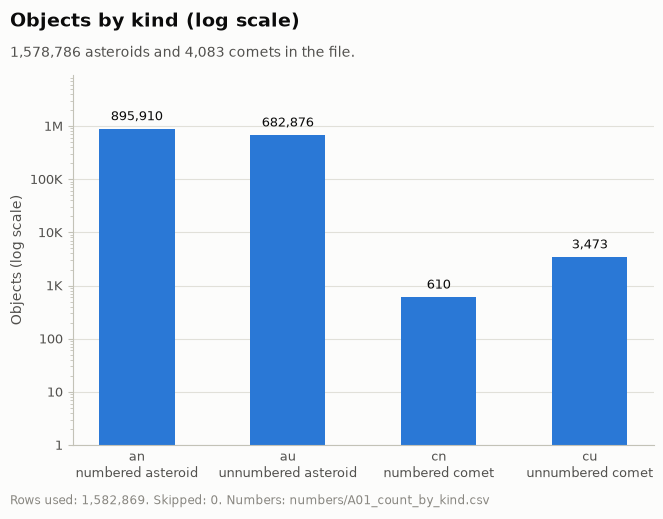

In [19]:
kc = d2["kind"].value_counts().reindex(KIND_ORDER)
n_ast, n_com = int(kc[["an", "au"]].sum()), int(kc[["cn", "cu"]].sum())
fig, ax = plt.subplots(figsize=(7.5, 4.8))
x = np.arange(len(kc))
ax.bar(x, kc.values, width=0.5, color=hp.SERIES[0])
for xi, v in zip(x, kc.values):
    ax.text(xi, v * 1.25, f"{v:,}", ha="center", va="bottom", fontsize=9.5, color=hp.INK)
ax.set_yscale("log")
ax.set_ylim(1, kc.max() * 10)
ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
ax.set_xticks(x, [f"{k}\n{KIND_NAME[k]}" for k in KIND_ORDER])
ax.set_ylabel("Objects (log scale)")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", length=0)
hp.add_titles(fig, "Objects by kind (log scale)",
              f"{n_ast:,} asteroids and {n_com:,} comets in the file.",
              hp.caption(n, 0, numbers_file="numbers/A01_count_by_kind.csv"))
c = hp.save_chart(fig, "A01_count_by_kind")
plt.show()
t = kc.rename_axis("kind").reset_index(name="objects")
t["meaning"] = t["kind"].map(KIND_NAME)
t["pct_of_rows"] = 100 * t["objects"] / n
hp.log_entry("A01", "Bar: objects by kind (log scale)", step=2, chart=c, numbers=hp.save_numbers(t, "A01_count_by_kind"),
             rows_used=n, rows_skipped=0,
             key_numbers=[", ".join(f"{k} {v:,}" for k, v in kc.items()),
                          f"asteroids {n_ast:,} ({100 * n_ast / n:.2f}%), comets {n_com:,} ({100 * n_com / n:.2f}%)"],
             what_it_shows=f"Almost every row is an asteroid; comets are {100 * n_com / n:.2f}% of the file. "
                           f"Numbered asteroids outnumber unnumbered ones {kc['an'] / kc['au']:.2f} to 1.")

### A02 Bar: objects by orbit class (log scale)

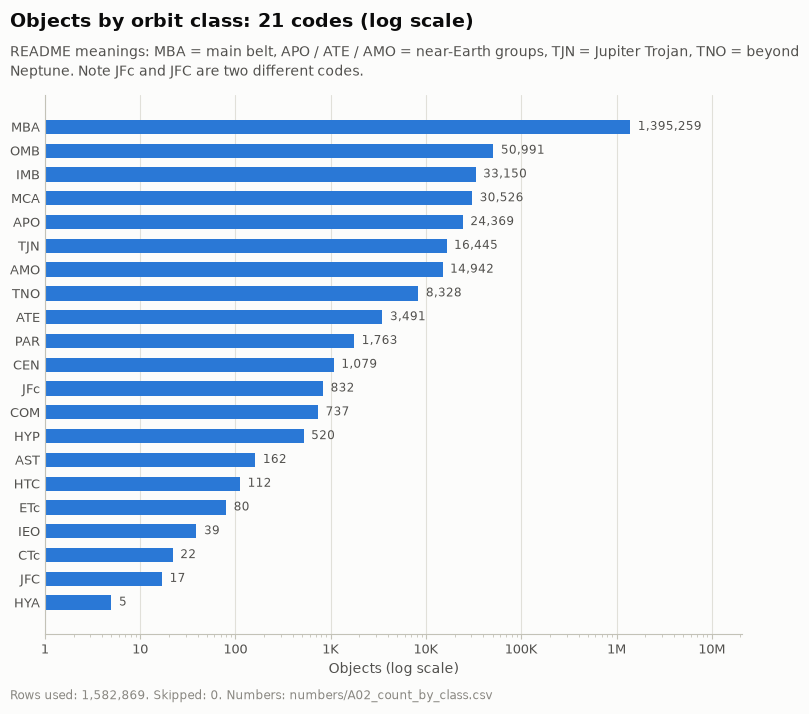

In [20]:
cls_c = d2["class"].value_counts()
fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(cls_c))[::-1]
ax.barh(yy, cls_c.values, height=0.6, color=hp.SERIES[0])
for yi, v in zip(yy, cls_c.values):
    ax.text(v * 1.2, yi, f"{v:,}", va="center", fontsize=8.5, color=hp.INK_2)
ax.set_xscale("log")
ax.set_xlim(1, cls_c.max() * 15)
ax.xaxis.set_major_formatter(FuncFormatter(hp.compact))
ax.set_yticks(yy, cls_c.index)
ax.set_xlabel("Objects (log scale)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
hp.add_titles(fig, f"Objects by orbit class: {len(cls_c)} codes (log scale)",
              "README meanings: MBA = main belt, APO / ATE / AMO = near-Earth groups, TJN = Jupiter Trojan, "
              "TNO = beyond Neptune. Note JFc and JFC are two different codes.",
              hp.caption(n, 0, numbers_file="numbers/A02_count_by_class.csv"))
c = hp.save_chart(fig, "A02_count_by_class")
plt.show()
t = cls_c.rename_axis("class").reset_index(name="objects")
t["pct_of_rows"] = 100 * t["objects"] / n
hp.log_entry("A02", "Bar: objects by orbit class (log scale)", step=2, chart=c,
             numbers=hp.save_numbers(t, "A02_count_by_class"), rows_used=n, rows_skipped=0,
             key_numbers=[f"{len(cls_c)} class codes",
                          "top 5: " + ", ".join(f"{k} {v:,}" for k, v in cls_c.head(5).items()),
                          "smallest 5: " + ", ".join(f"{k} {v:,}" for k, v in cls_c.tail(5).items()),
                          f"MBA share: {100 * cls_c['MBA'] / n:.1f}% of rows"],
             what_it_shows=f"One class, MBA (main belt), holds {100 * cls_c['MBA'] / n:.1f}% of all rows; "
                           f"the counts fall over {np.log10(cls_c.max() / cls_c.min()):.1f} powers of ten "
                           f"down to {cls_c.index[-1]} with {cls_c.iloc[-1]}.")

### A03 Histogram: brightness H (bins of 0.5)

Lower H = brighter = bigger. Top panel: normal scale. Bottom panel: the same counts on a log scale,
because the counts run from 1 to over 100,000 per bin.

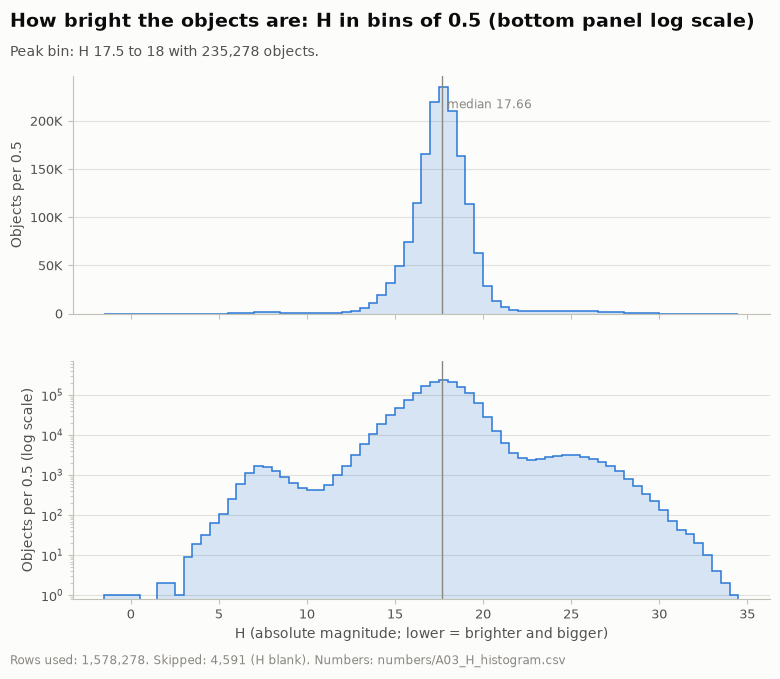

In [21]:
Hs = d2["H"].dropna()
h_edges = np.arange(np.floor(Hs.min() * 2) / 2, np.ceil(Hs.max() * 2) / 2 + 0.25, 0.5)
h_cnt, _ = np.histogram(Hs, bins=h_edges)
peak = int(np.argmax(h_cnt))
fig, axs = plt.subplots(2, 1, figsize=(9, 6.8), sharex=True)
for ax, logy in zip(axs, [False, True]):
    hp.draw_hist(ax, h_cnt, h_edges)
    ax.axvline(Hs.median(), color=hp.INK_MUTED, lw=1)
    ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
    ax.grid(axis="x", visible=False)
    if logy:
        ax.set_yscale("log")
        ax.set_ylim(0.8, h_cnt.max() * 3)
        ax.set_ylabel("Objects per 0.5 (log scale)")
    else:
        ax.set_ylabel("Objects per 0.5")
        ax.text(Hs.median() + 0.3, h_cnt.max() * 0.95, f"median {Hs.median():.2f}", fontsize=8.5,
                color=hp.INK_MUTED, va="top")
axs[1].set_xlabel("H (absolute magnitude; lower = brighter and bigger)")
hp.add_titles(fig, "How bright the objects are: H in bins of 0.5 (bottom panel log scale)",
              f"Peak bin: H {h_edges[peak]:g} to {h_edges[peak + 1]:g} with {h_cnt[peak]:,} objects.",
              hp.caption(len(Hs), n - len(Hs), "H blank", "numbers/A03_H_histogram.csv"))
c = hp.save_chart(fig, "A03_H_histogram")
plt.show()
t = pd.DataFrame({"H_from": h_edges[:-1], "H_to": h_edges[1:], "objects": h_cnt})
hp.log_entry("A03", "Histogram: H, bins of 0.5", step=2, chart=c, numbers=hp.save_numbers(t, "A03_H_histogram"),
             rows_used=len(Hs), rows_skipped=f"{n - len(Hs):,} (H blank)",
             key_numbers=[f"min {Hs.min():g}, median {Hs.median():g}, max {Hs.max():g}",
                          f"peak bin H {h_edges[peak]:g}-{h_edges[peak + 1]:g}: {h_cnt[peak]:,}",
                          f"H < 10: {int((Hs < 10).sum()):,}; H >= 25: {int((Hs >= 25).sum()):,}"],
             what_it_shows=f"Counts climb steadily with H up to a peak at H {h_edges[peak]:g}-{h_edges[peak + 1]:g}, "
                           f"then fall off fast; only {int((Hs >= 25).sum()):,} objects have H of 25 or more.")

### A04 Histograms: eccentricity e (0 to 1) and tilt i (0 to 180 degrees)

e = how stretched the orbit is (0 = circle). Only closed orbits (e < 1) fit on this axis.
i = tilt of the orbit against Earth's orbit; above 90 degrees the object goes round the "wrong" way.
Both counts run over several powers of ten, so both y axes are log scale.

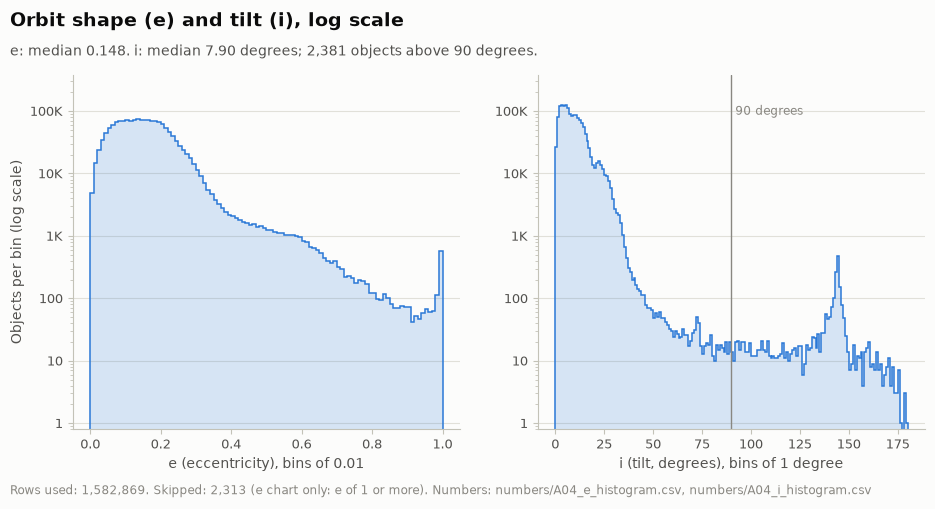

In [22]:
e_ok = d2["e"] < 1
e_edges = np.round(np.arange(0, 101) / 100, 2)
e_cnt, _ = np.histogram(d2.loc[e_ok, "e"], bins=e_edges)
i_edges = np.arange(0, 181, 1.0)
i_cnt, _ = np.histogram(d2["i"], bins=i_edges)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
hp.draw_hist(axs[0], e_cnt, e_edges)
hp.draw_hist(axs[1], i_cnt, i_edges)
axs[0].set_xlabel("e (eccentricity), bins of 0.01")
axs[1].set_xlabel("i (tilt, degrees), bins of 1 degree")
axs[1].axvline(90, color=hp.INK_MUTED, lw=1)
axs[1].text(92, i_cnt.max(), "90 degrees", fontsize=8.5, color=hp.INK_MUTED, va="top")
for ax in axs:
    ax.set_yscale("log")
    ax.set_ylim(0.8, max(e_cnt.max(), i_cnt.max()) * 3)
    ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("Objects per bin (log scale)")
n_open = int((~e_ok).sum())
hp.add_titles(fig, "Orbit shape (e) and tilt (i), log scale",
              f"e: median {d2.loc[e_ok, 'e'].median():.3f}. i: median {d2['i'].median():.2f} degrees; "
              f"{int((d2['i'] > 90).sum()):,} objects above 90 degrees.",
              hp.caption(n, n_open, "e chart only: e of 1 or more", "numbers/A04_e_histogram.csv, numbers/A04_i_histogram.csv"))
c = hp.save_chart(fig, "A04_e_and_i_histograms")
plt.show()
f1 = hp.save_numbers(pd.DataFrame({"e_from": e_edges[:-1], "e_to": e_edges[1:], "objects": e_cnt}), "A04_e_histogram")
f2 = hp.save_numbers(pd.DataFrame({"i_from": i_edges[:-1], "i_to": i_edges[1:], "objects": i_cnt}), "A04_i_histogram")
pk_e, pk_i = int(np.argmax(e_cnt)), int(np.argmax(i_cnt))
hp.log_entry("A04", "Histograms: e (0-1) and i (0-180)", step=2, chart=c, numbers=[f1, f2],
             rows_used=f"e: {int(e_ok.sum()):,}; i: {n:,}", rows_skipped=f"e: {n_open:,} (e >= 1); i: 0",
             key_numbers=[f"e median {d2.loc[e_ok, 'e'].median():.4f}; peak bin {e_edges[pk_e]:.2f}-{e_edges[pk_e + 1]:.2f} ({e_cnt[pk_e]:,})",
                          f"e < 0.3: {100 * (d2.loc[e_ok, 'e'] < 0.3).mean():.1f}% of closed orbits",
                          f"i median {d2['i'].median():.2f}; peak bin {i_edges[pk_i]:g}-{i_edges[pk_i + 1]:g} ({i_cnt[pk_i]:,})",
                          f"i < 30: {100 * (d2['i'] < 30).mean():.1f}%; i > 90: {int((d2['i'] > 90).sum()):,}"],
             what_it_shows=f"Most orbits are close to circles ({100 * (d2.loc[e_ok, 'e'] < 0.3).mean():.1f}% have e < 0.3) "
                           f"and only slightly tilted ({100 * (d2['i'] < 30).mean():.1f}% under 30 degrees); "
                           f"{int((d2['i'] > 90).sum()):,} go round backwards (i > 90).")

### A05 Histogram: distance from the Sun, a = 1.7 to 5.5 AU (bins of 0.01, log scale)

a = average distance from the Sun in AU (1 AU = Earth to Sun). Asteroids only (`kind` an or au), closed orbits only (e < 1).

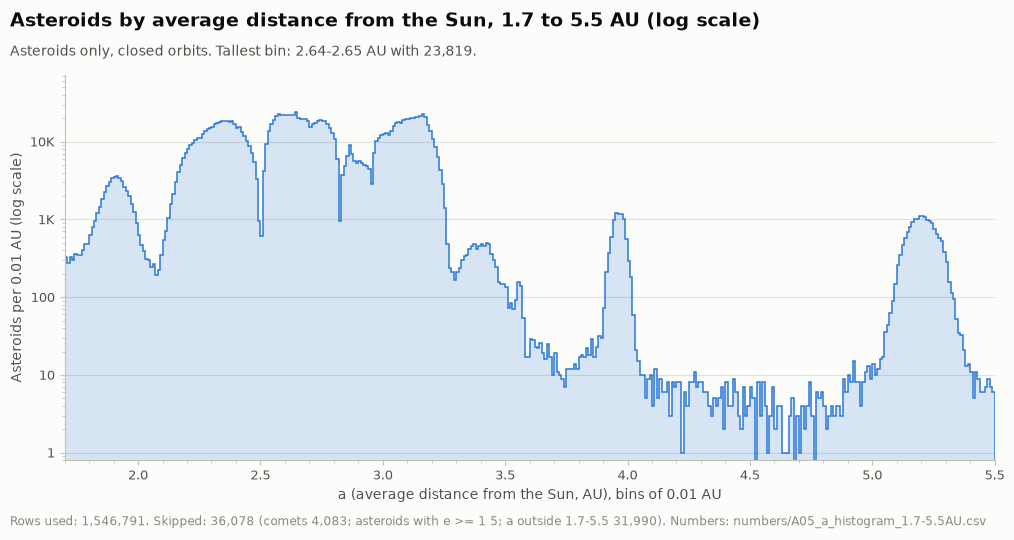

In [23]:
in5 = is_ast2 & (d2["e"] < 1) & (d2["a"] >= 1.7) & (d2["a"] < 5.5)
a5 = d2.loc[in5, "a"]
edges5 = np.round(np.arange(170, 551) / 100, 2)
cnt5, _ = np.histogram(a5, bins=edges5)
skip5 = {"comets": int((~is_ast2).sum()), "asteroids with e >= 1": int((is_ast2 & (d2["e"] >= 1)).sum()),
         "a outside 1.7-5.5": int((is_ast2 & (d2["e"] < 1) & ~((d2["a"] >= 1.7) & (d2["a"] < 5.5))).sum())}
fig, ax = plt.subplots(figsize=(12, 5))
hp.draw_hist(ax, cnt5, edges5)
ax.set_yscale("log")
ax.set_ylim(0.8, cnt5.max() * 3)
ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
ax.set_xlim(1.7, 5.5)
ax.set_xticks(np.arange(1.7, 5.51, 0.1), minor=True)
ax.set_xlabel("a (average distance from the Sun, AU), bins of 0.01 AU")
ax.set_ylabel("Asteroids per 0.01 AU (log scale)")
ax.grid(axis="x", visible=False)
pk5 = int(np.argmax(cnt5))
hp.add_titles(fig, "Asteroids by average distance from the Sun, 1.7 to 5.5 AU (log scale)",
              f"Asteroids only, closed orbits. Tallest bin: {edges5[pk5]:.2f}-{edges5[pk5 + 1]:.2f} AU with {cnt5[pk5]:,}.",
              hp.caption(len(a5), n - len(a5), "; ".join(f"{k} {v:,}" for k, v in skip5.items()),
                         "numbers/A05_a_histogram_1.7-5.5AU.csv"))
c = hp.save_chart(fig, "A05_a_histogram_1.7-5.5AU")
plt.show()
t = pd.DataFrame({"a_from": edges5[:-1], "a_to": edges5[1:], "asteroids": cnt5})
hp.log_entry("A05", "Histogram: a from 1.7 to 5.5 AU, bins of 0.01, log y (asteroids, e < 1)", step=2, chart=c,
             numbers=hp.save_numbers(t, "A05_a_histogram_1.7-5.5AU"), rows_used=len(a5),
             rows_skipped=f"{n - len(a5):,} (" + "; ".join(f"{k} {v:,}" for k, v in skip5.items()) + ")",
             key_numbers=[f"tallest bin {edges5[pk5]:.2f}-{edges5[pk5 + 1]:.2f} AU: {cnt5[pk5]:,}",
                          f"empty bins: {int((cnt5 == 0).sum())} of {len(cnt5)}",
                          f"between 2.0 and 3.3 AU: {int(((a5 >= 2.0) & (a5 < 3.3)).sum()):,} ({100 * ((a5 >= 2.0) & (a5 < 3.3)).mean():.1f}%)"],
             what_it_shows=f"Most asteroids sit between 2.0 and 3.3 AU ({100 * ((a5 >= 2.0) & (a5 < 3.3)).mean():.1f}%), "
                           "and the curve is not smooth: it has narrow, deep dips and separate bumps further out (listed in Step 4).")

### A06 Histogram: a = 30 to 60 AU (bins of 0.25)

The far zone past Neptune (Neptune is at about 30 AU). All objects with closed orbits (asteroids and comets).

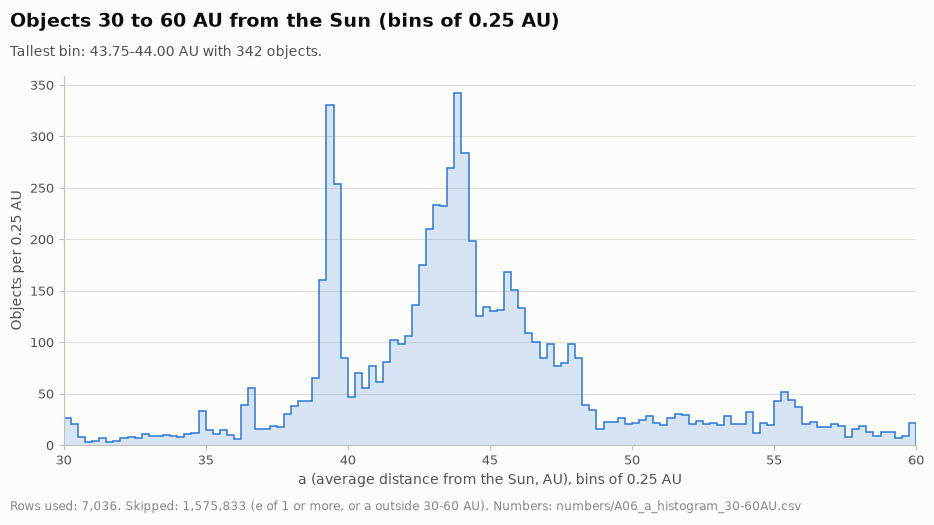

In [24]:
in6 = (d2["e"] < 1) & (d2["a"] >= 30) & (d2["a"] < 60)
a6 = d2.loc[in6, "a"]
edges6 = np.arange(30, 60.001, 0.25)
cnt6, _ = np.histogram(a6, bins=edges6)
pk6 = int(np.argmax(cnt6))
fig, ax = plt.subplots(figsize=(11, 4.8))
hp.draw_hist(ax, cnt6, edges6)
ax.set_xlabel("a (average distance from the Sun, AU), bins of 0.25 AU")
ax.set_ylabel("Objects per 0.25 AU")
ax.grid(axis="x", visible=False)
ax.set_xlim(30, 60)
hp.add_titles(fig, "Objects 30 to 60 AU from the Sun (bins of 0.25 AU)",
              f"Tallest bin: {edges6[pk6]:.2f}-{edges6[pk6 + 1]:.2f} AU with {cnt6[pk6]:,} objects.",
              hp.caption(len(a6), n - len(a6), "e of 1 or more, or a outside 30-60 AU", "numbers/A06_a_histogram_30-60AU.csv"))
c = hp.save_chart(fig, "A06_a_histogram_30-60AU")
plt.show()
t = pd.DataFrame({"a_from": edges6[:-1], "a_to": edges6[1:], "objects": cnt6})
hp.log_entry("A06", "Histogram: a from 30 to 60 AU, bins of 0.25", step=2, chart=c,
             numbers=hp.save_numbers(t, "A06_a_histogram_30-60AU"), rows_used=len(a6),
             rows_skipped=f"{n - len(a6):,} (e >= 1 or a outside 30-60 AU)",
             key_numbers=[f"objects with 30 <= a < 60 AU: {len(a6):,}",
                          f"tallest bin {edges6[pk6]:.2f}-{edges6[pk6 + 1]:.2f}: {cnt6[pk6]:,}",
                          f"42-48 AU: {int(((a6 >= 42) & (a6 < 48)).sum()):,}; 48-60 AU: {int(((a6 >= 48) & (a6 < 60)).sum()):,}"],
             what_it_shows=f"The tallest single bin is {edges6[pk6]:.2f}-{edges6[pk6 + 1]:.2f} AU; most of the rest "
                           f"sit in a wide hump between 42 and 48 AU ({int(((a6 >= 42) & (a6 < 48)).sum()):,} objects), "
                           f"with only {int(((a6 >= 48) & (a6 < 60)).sum()):,} beyond 48 AU.")

### A07 Histograms: diameter (log bins), albedo, rotation period (log bins)

These three columns are blank for most rows (Step 1), so each panel uses only the rows that have the value.
Diameter and rotation period cover many powers of ten, so their bins are equal steps on a log scale (10 per power of ten).

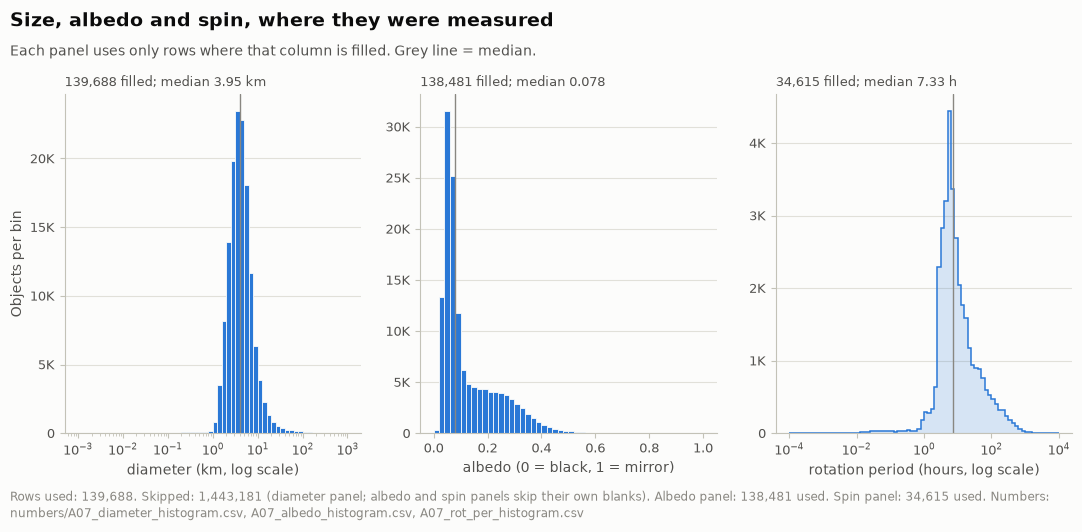

In [25]:
dia, alb, rot = d2["diameter"].dropna(), d2["albedo"].dropna(), d2["rot_per"].dropna()
dia_edges = 10 ** np.round(np.arange(-30, 31) / 10, 1)   # 0.001 to 1000 km
alb_edges = np.round(np.arange(0, 51) / 50, 2)            # bins of 0.02
rot_edges = 10 ** np.round(np.arange(-40, 41) / 10, 1)   # 0.0001 to 10,000 hours
dia_cnt, _ = np.histogram(dia, bins=dia_edges)
alb_cnt, _ = np.histogram(alb, bins=alb_edges)
rot_cnt, _ = np.histogram(rot, bins=rot_edges)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, cnt, edges, lab, logx in [(axs[0], dia_cnt, dia_edges, "diameter (km, log scale)", True),
                                  (axs[1], alb_cnt, alb_edges, "albedo (0 = black, 1 = mirror)", False),
                                  (axs[2], rot_cnt, rot_edges, "rotation period (hours, log scale)", True)]:
    hp.draw_hist(ax, cnt, edges)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(lab)
    ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("Objects per bin")
for ax, s, unit in [(axs[0], dia, " km"), (axs[1], alb, ""), (axs[2], rot, " h")]:
    ax.axvline(s.median(), color=hp.INK_MUTED, lw=1)
    ax.set_title(f"{len(s):,} filled; median {s.median():g}{unit}", fontsize=9.5, color=hp.INK_2)
hp.add_titles(fig, "Size, albedo and spin, where they were measured",
              "Each panel uses only rows where that column is filled. Grey line = median.",
              hp.caption(len(dia), n - len(dia), "diameter panel; albedo and spin panels skip their own blanks", "",
                         extra=f"Albedo panel: {len(alb):,} used. Spin panel: {len(rot):,} used. "
                               "Numbers: numbers/A07_diameter_histogram.csv, A07_albedo_histogram.csv, A07_rot_per_histogram.csv"))
c = hp.save_chart(fig, "A07_diameter_albedo_spin_histograms")
plt.show()
f1 = hp.save_numbers(pd.DataFrame({"km_from": dia_edges[:-1], "km_to": dia_edges[1:], "objects": dia_cnt}), "A07_diameter_histogram")
f2 = hp.save_numbers(pd.DataFrame({"albedo_from": alb_edges[:-1], "albedo_to": alb_edges[1:], "objects": alb_cnt}), "A07_albedo_histogram")
f3 = hp.save_numbers(pd.DataFrame({"hours_from": rot_edges[:-1], "hours_to": rot_edges[1:], "objects": rot_cnt}), "A07_rot_per_histogram")
pa = int(np.argmax(alb_cnt))
hp.log_entry("A07", "Histograms: diameter (log bins), albedo, rot_per (log bins)", step=2, chart=c, numbers=[f1, f2, f3],
             rows_used=f"diameter {len(dia):,}; albedo {len(alb):,}; rot_per {len(rot):,}",
             rows_skipped=f"diameter {n - len(dia):,}; albedo {n - len(alb):,}; rot_per {n - len(rot):,} (blank)",
             key_numbers=[f"diameter: median {dia.median():g} km, from {dia.min():g} to {dia.max():g} km",
                          f"albedo: median {alb.median():g}; tallest bin {alb_edges[pa]:.2f}-{alb_edges[pa + 1]:.2f} ({alb_cnt[pa]:,}); "
                          f"above 0.15: {100 * (alb > 0.15).mean():.1f}%",
                          f"rot_per: median {rot.median():g} h; under 2.2 h: {int((rot < 2.2).sum()):,} "
                          f"({100 * (rot < 2.2).mean():.1f}%); from {rot.min():g} to {rot.max():g} h"],
             what_it_shows=f"Measured sizes centre on a few km (median {dia.median():g} km); albedo is mostly dark "
                           f"(median {alb.median():g}) with a long bright tail; spin periods centre on {rot.median():g} hours.")

### A08 Bar: orbit uncertainty (condition_code), one panel per kind

condition_code: 0 = very certain orbit, 9 = very uncertain (README). Each panel has its own y scale,
because the four kinds have very different sizes.

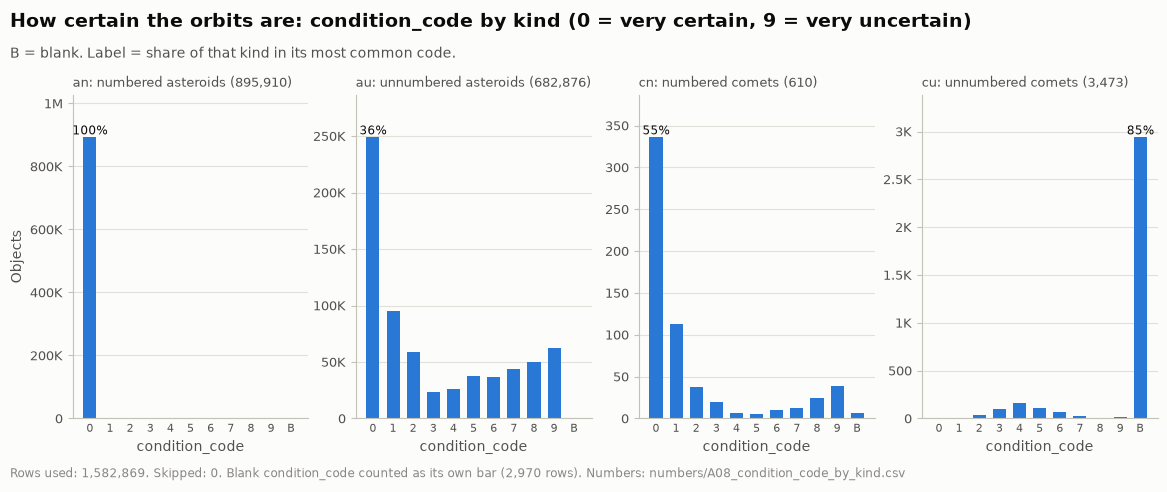

In [26]:
cc_lab = [str(k) for k in range(10)] + ["B"]  # B = blank
cc_tab = pd.crosstab(d2["condition_code"].fillna(-1).astype(int), d2["kind"]).reindex(index=list(range(10)) + [-1], columns=KIND_ORDER, fill_value=0)
cc_tab.index = cc_lab
fig, axs = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, k in zip(axs, KIND_ORDER):
    vals = cc_tab[k].values
    ax.bar(np.arange(len(cc_lab)), vals, width=0.65, color=hp.SERIES[0])
    top = int(np.argmax(vals))
    ax.text(top, vals[top], f"{100 * vals[top] / vals.sum():.0f}%", ha="center", va="bottom", fontsize=8.5, color=hp.INK)
    ax.set_xticks(np.arange(len(cc_lab)), cc_lab, fontsize=8)
    ax.set_title(f"{k}: {KIND_NAME[k]}s ({vals.sum():,})", fontsize=9.5, color=hp.INK_2)
    ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
    ax.set_xlabel("condition_code")
    ax.set_ylim(0, vals.max() * 1.15)
axs[0].set_ylabel("Objects")
hp.add_titles(fig, "How certain the orbits are: condition_code by kind (0 = very certain, 9 = very uncertain)",
              "B = blank. Label = share of that kind in its most common code.",
              hp.caption(n, 0, numbers_file="numbers/A08_condition_code_by_kind.csv",
                         extra=f"Blank condition_code counted as its own bar ({int(d2['condition_code'].isna().sum()):,} rows)."))
c = hp.save_chart(fig, "A08_condition_code_by_kind")
plt.show()
t = cc_tab.rename_axis("condition_code").reset_index()
share0 = 100 * cc_tab.loc["0"] / cc_tab.sum()
hp.log_entry("A08", "Bar: condition_code counts, split by kind", step=2, chart=c,
             numbers=hp.save_numbers(t, "A08_condition_code_by_kind"), rows_used=n,
             rows_skipped="0 (blank condition_code shown as its own bar)",
             key_numbers=["code 0 share: " + ", ".join(f"{k} {share0[k]:.1f}%" for k in KIND_ORDER),
                          f"au with code 5-9: {int(cc_tab.loc[['5', '6', '7', '8', '9'], 'au'].sum()):,} "
                          f"({100 * cc_tab.loc[['5', '6', '7', '8', '9'], 'au'].sum() / cc_tab['au'].sum():.1f}% of au)",
                          f"blank: " + ", ".join(f"{k} {int(cc_tab.loc['B', k]):,}" for k in KIND_ORDER)],
             what_it_shows=f"Numbered asteroids are almost all code 0 ({share0['an']:.1f}%); unnumbered asteroids spread "
                           f"across all codes, with {100 * cc_tab.loc[['5', '6', '7', '8', '9'], 'au'].sum() / cc_tab['au'].sum():.1f}% at 5-9.")
hp.progress("A", 2)

## Step 3: Two labels together

Scatter, line and 2D charts that put two columns side by side. The columns these charts need are read once.

In [27]:
from matplotlib.colors import LogNorm
from scipy import ndimage

del d2
COLS3 = ["full_name", "name", "kind", "class", "neo", "pha", "H", "diameter", "albedo", "rot_per",
         "e", "a", "q", "i", "om", "w", "ma", "moid", "first_obs", "n_obs_used"]
hp.tick("Step 3 start")
d3 = hp.read_csv("asteroids", usecols=COLS3)
hp.tick("Step 3 columns read")
is_ast = d3["kind"].isin(["an", "au"])
closed = d3["e"] < 1
yr = hp.year_from_text(d3["first_obs"])
print(f"{len(d3):,} rows x {d3.shape[1]} columns")

[Step 3 start] +13.9s, memory 1,264 MB


[Step 3 columns read] +3.1s, memory 1,424 MB


1,582,869 rows x 20 columns


### A09 2D histogram: distance a (1.8 to 3.6 AU) against tilt i (0 to 35 degrees), main belt

Each cell counts asteroids in a 0.005 AU x 0.1 degree box. Colour is log scale. Asteroids only, closed orbits.

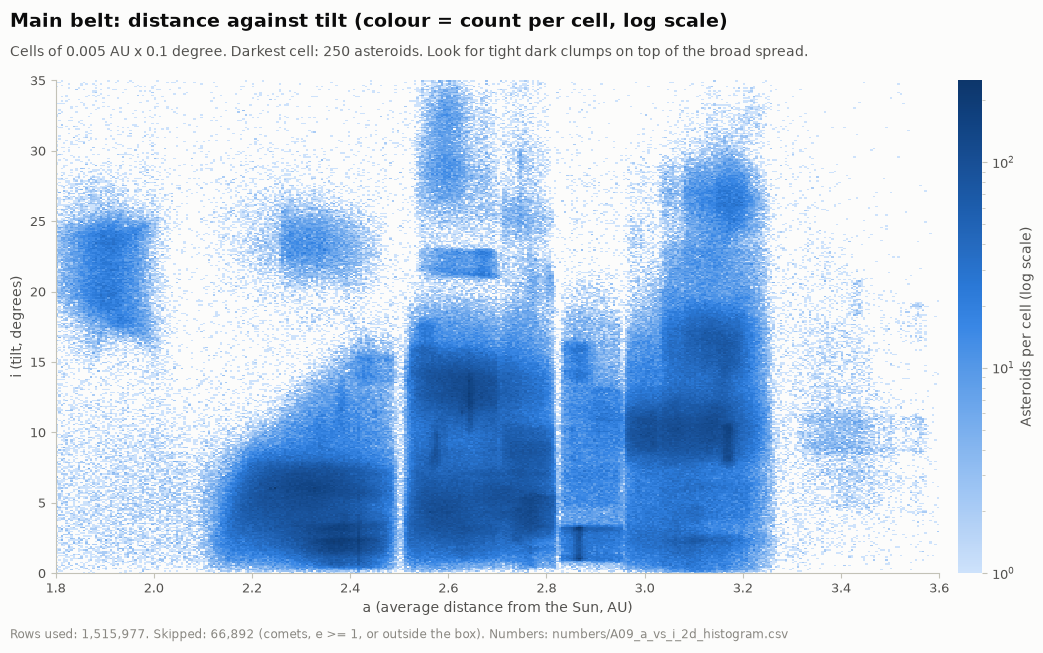

Clumps (densest relative to their surroundings):
      a_AU  i_deg  density_vs_surroundings  smoothed_count_per_cell  asteroids_in_box
0   2.8675   1.15                     3.02                     62.1              2984
1   2.8675   3.05                     2.86                     89.1              4435
2   3.1025   2.25                     1.98                     57.5              3484
3   3.1675  10.25                     1.96                    126.2              7194
4   3.1725   8.25                     1.96                     86.0              4743
5   2.3725   2.15                     1.95                    169.7             10795
6   2.7725   5.15                     1.80                    115.7              7185
7   2.5725   8.45                     1.79                     68.5              3909
8   2.6425  12.55                     1.78                    135.0              8053
9   3.1675  16.35                     1.77                     67.7              4178
10  2

In [28]:
in9 = is_ast & closed & (d3["a"] >= 1.8) & (d3["a"] < 3.6) & (d3["i"] >= 0) & (d3["i"] < 35)
a_edges9 = np.round(np.arange(1800, 3601, 5) / 1000, 3)
i_edges9 = np.round(np.arange(0, 351) / 10, 1)
H9, _, _ = np.histogram2d(d3.loc[in9, "a"], d3.loc[in9, "i"], bins=[a_edges9, i_edges9])
cmap9 = hp.seq_cmap(start_at_surface=False)
cmap9.set_bad(hp.SURFACE)
fig, ax = plt.subplots(figsize=(12, 6.4))
im = ax.pcolormesh(a_edges9, i_edges9, np.ma.masked_equal(H9.T, 0), cmap=cmap9,
                   norm=LogNorm(vmin=1, vmax=H9.max()), rasterized=True)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("Asteroids per cell (log scale)")
cb.outline.set_visible(False)
ax.set_xlabel("a (average distance from the Sun, AU)")
ax.set_ylabel("i (tilt, degrees)")
ax.grid(False)
hp.add_titles(fig, "Main belt: distance against tilt (colour = count per cell, log scale)",
              f"Cells of 0.005 AU x 0.1 degree. Darkest cell: {int(H9.max()):,} asteroids. "
              "Look for tight dark clumps on top of the broad spread.",
              hp.caption(int(in9.sum()), n - int(in9.sum()), "comets, e >= 1, or outside the box",
                         "numbers/A09_a_vs_i_2d_histogram.csv"))
c = hp.save_chart(fig, "A09_a_vs_i_2d_histogram")
plt.show()

# numbers: the non-empty cells (a, i, count)
ia, ii = np.nonzero(H9)
t9 = pd.DataFrame({"a_from": a_edges9[ia], "i_from": i_edges9[ii], "asteroids": H9[ia, ii].astype(int)})

# Clump finder: compare each spot with its wider surroundings (smoothed over 2 cells, against smoothed over 12 cells).
# A family shows up as a spot much denser than its surroundings.
near = ndimage.gaussian_filter(H9, 2)
wide = ndimage.gaussian_filter(H9, 12)
contrast = near / np.maximum(wide, 1e-9)
peaks = (contrast == ndimage.maximum_filter(contrast, size=(15, 21))) & (near >= 30) & (contrast >= 1.6)
pa_, pi_ = np.nonzero(peaks)
clumps = pd.DataFrame({"a_AU": a_edges9[pa_] + 0.0025, "i_deg": i_edges9[pi_] + 0.05,
                       "density_vs_surroundings": contrast[pa_, pi_].round(2), "smoothed_count_per_cell": near[pa_, pi_].round(1)})
# asteroids inside a small box around each clump centre (+-0.02 AU, +-0.4 degrees)
clumps["asteroids_in_box"] = [int(((d3.loc[in9, "a"] - ca).abs() <= 0.02).mul((d3.loc[in9, "i"] - ci).abs() <= 0.4).sum())
                              for ca, ci in zip(clumps["a_AU"], clumps["i_deg"])]
clumps = clumps.sort_values("density_vs_surroundings", ascending=False).head(12).reset_index(drop=True)
print("Clumps (densest relative to their surroundings):")
print(clumps.to_string())
nf = [hp.save_numbers(t9, "A09_a_vs_i_2d_histogram"), hp.save_numbers(clumps, "A09_clumps")]
hp.log_entry("A09", "2D histogram: a (1.8-3.6) against i (0-35), main belt", step=3, chart=c, numbers=nf,
             rows_used=int(in9.sum()), rows_skipped=f"{n - int(in9.sum()):,} (comets, e >= 1, or outside the a/i box)",
             key_numbers=[f"darkest cell: {int(H9.max()):,} asteroids",
                          f"clumps found by the finder: {len(clumps)}",
                          "top clumps (a, i, density vs surroundings): " + "; ".join(
                              f"{r.a_AU:.3f} AU {r.i_deg:.1f} deg x{r.density_vs_surroundings}" for r in clumps.head(6).itertuples())],
             what_it_shows=f"On top of the broad belt there are tight clumps; the strongest sits at a = {clumps.a_AU[0]:.3f} AU, "
                           f"i = {clumps.i_deg[0]:.1f} degrees, {clumps.density_vs_surroundings[0]:.1f} times denser than its surroundings.")

### A10 Line: median albedo per 0.05 AU of distance (1.8 to 3.6 AU), with the count per bin

Albedo = how much sunlight the surface reflects. Asteroids with a measured albedo only, closed orbits.

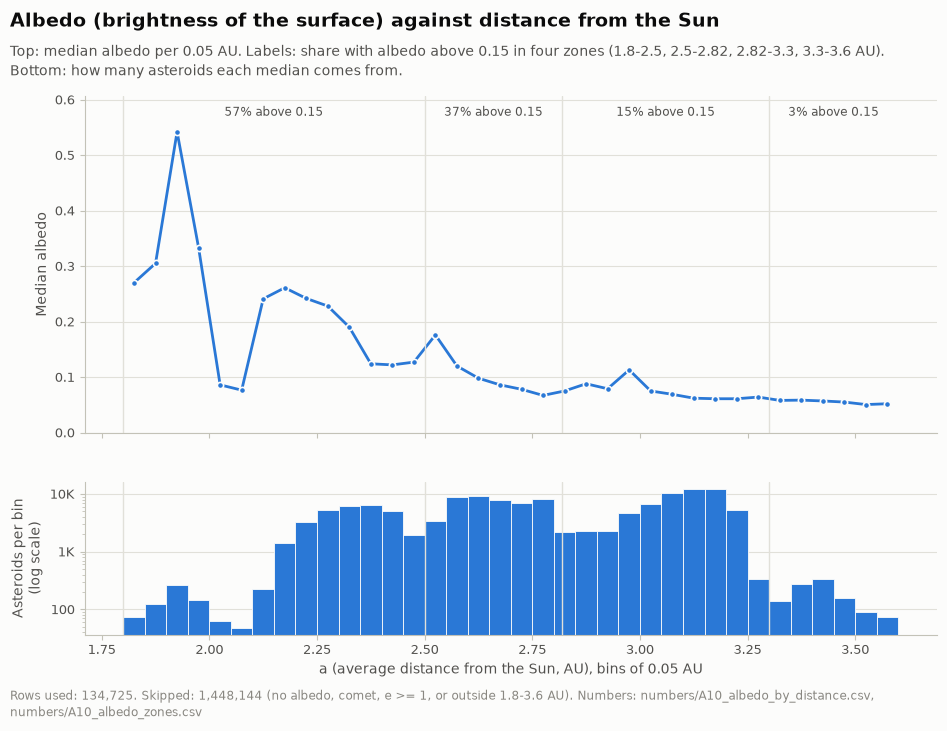

       zone  asteroids_with_albedo  pct_albedo_above_0.15  median_albedo
 1.8-2.5 AU                  30533                 56.545          0.192
2.5-2.82 AU                  45910                 36.685          0.086
2.82-3.3 AU                  57211                 14.562          0.066
 3.3-3.6 AU                   1071                  2.708          0.056


In [29]:
in10 = is_ast & closed & d3["albedo"].notna() & (d3["a"] >= 1.8) & (d3["a"] < 3.6)
edges10 = np.round(np.arange(180, 361, 5) / 100, 2)
bin10 = pd.cut(d3.loc[in10, "a"], edges10, right=False)
g10 = d3.loc[in10, "albedo"].groupby(bin10, observed=False)
t10 = pd.DataFrame({"a_from": edges10[:-1], "a_to": edges10[1:], "median_albedo": g10.median().values,
                    "asteroids_with_albedo": g10.size().values,
                    "pct_above_0.15": (100 * d3.loc[in10, "albedo"].gt(0.15).groupby(bin10, observed=False).mean()).values})
ZONES = [(1.8, 2.5), (2.5, 2.82), (2.82, 3.3), (3.3, 3.6)]
zone_rows = []
for lo, hi in ZONES:
    z = in10 & (d3["a"] >= lo) & (d3["a"] < hi)
    zone_rows.append({"zone": f"{lo}-{hi} AU", "asteroids_with_albedo": int(z.sum()),
                      "pct_albedo_above_0.15": 100 * (d3.loc[z, "albedo"] > 0.15).mean(),
                      "median_albedo": d3.loc[z, "albedo"].median()})
zones10 = pd.DataFrame(zone_rows)
mid10 = (edges10[:-1] + edges10[1:]) / 2
fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
axs[0].plot(mid10, t10["median_albedo"], color=hp.SERIES[0], marker="o", ms=4.5, mec=hp.SURFACE, mew=1.2)
for (lo, hi), zr in zip(ZONES, zone_rows):
    for ax in axs:
        ax.axvline(lo, color=hp.GRID, lw=1)
    axs[0].text((lo + hi) / 2, axs[0].get_ylim()[1] if False else 0.0, "", fontsize=1)
ytop = np.nanmax(t10["median_albedo"]) * 1.12
axs[0].set_ylim(0, ytop)
for (lo, hi), zr in zip(ZONES, zone_rows):
    axs[0].text((lo + hi) / 2, ytop * 0.97, f"{zr['pct_albedo_above_0.15']:.0f}% above 0.15", ha="center", va="top",
                fontsize=8.5, color=hp.INK_2)
axs[0].set_ylabel("Median albedo")
axs[1].bar(edges10[:-1], t10["asteroids_with_albedo"], width=0.05, align="edge", color=hp.SERIES[0],
           edgecolor=hp.SURFACE, linewidth=0.6)
axs[1].set_yscale("log")
axs[1].yaxis.set_major_formatter(FuncFormatter(hp.compact))
axs[1].set_ylabel("Asteroids per bin\n(log scale)")
axs[1].set_xlabel("a (average distance from the Sun, AU), bins of 0.05 AU")
for ax in axs:
    ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Albedo (brightness of the surface) against distance from the Sun",
              "Top: median albedo per 0.05 AU. Labels: share with albedo above 0.15 in four zones "
              "(1.8-2.5, 2.5-2.82, 2.82-3.3, 3.3-3.6 AU). Bottom: how many asteroids each median comes from.",
              hp.caption(int(in10.sum()), n - int(in10.sum()), "no albedo, comet, e >= 1, or outside 1.8-3.6 AU",
                         "numbers/A10_albedo_by_distance.csv, numbers/A10_albedo_zones.csv"))
c = hp.save_chart(fig, "A10_albedo_by_distance")
plt.show()
print(zones10.round(3).to_string(index=False))
nf = [hp.save_numbers(t10, "A10_albedo_by_distance"), hp.save_numbers(zones10, "A10_albedo_zones")]
hp.log_entry("A10", "Line: median albedo per 0.05 AU of a (1.8-3.6), with count per bin", step=3, chart=c, numbers=nf,
             rows_used=int(in10.sum()), rows_skipped=f"{n - int(in10.sum()):,} (no albedo, comet, e >= 1, or a outside 1.8-3.6)",
             key_numbers=["% with albedo above 0.15: " + ", ".join(f"{r['zone']} {r['pct_albedo_above_0.15']:.1f}%" for r in zone_rows),
                          f"highest median: {t10['median_albedo'].max():.3f} at {t10.loc[t10['median_albedo'].idxmax(), 'a_from']:.2f} AU "
                          f"({int(t10.loc[t10['median_albedo'].idxmax(), 'asteroids_with_albedo']):,} asteroids)",
                          f"fewest asteroids in a bin: {int(t10['asteroids_with_albedo'].min()):,}"],
             what_it_shows="The share of bright surfaces falls zone by zone with distance: "
                           + " -> ".join(f"{r['pct_albedo_above_0.15']:.0f}%" for r in zone_rows) + ".")

### A11 Scatter (both axes log): size against spin period

Size = measured `diameter`; where that is blank, size is estimated from brightness:
D_km = 1329 / sqrt(albedo) x 10^(-H/5) with albedo assumed 0.14. The line marks 2.2 hours per spin.

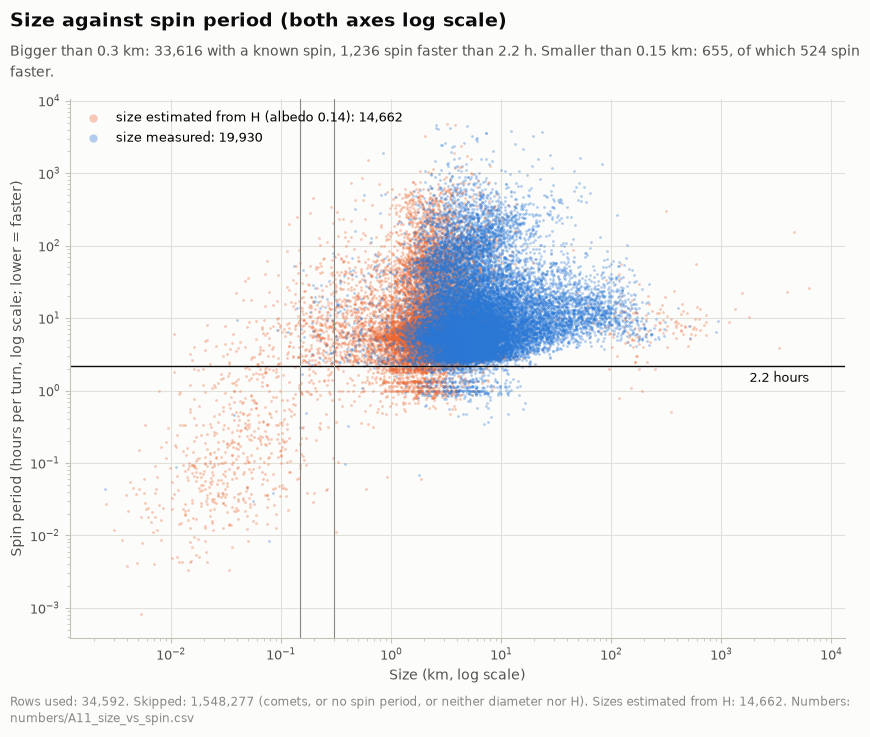

In [30]:
in11 = is_ast & d3["rot_per"].notna() & (d3["diameter"].notna() | d3["H"].notna())
s11 = d3.loc[in11, ["full_name", "diameter", "H", "rot_per"]].copy()
s11["estimated"] = s11["diameter"].isna()
s11["size_km"] = s11["diameter"].where(~s11["estimated"], hp.size_from_H(s11["H"], 0.14))
big, small, fast = s11["size_km"] > 0.3, s11["size_km"] < 0.15, s11["rot_per"] < 2.2
n_big, n_big_fast, n_small, n_small_fast = int(big.sum()), int((big & fast).sum()), int(small.sum()), int((small & fast).sum())
fig, ax = plt.subplots(figsize=(10, 7))
for est, col, lab in [(True, hp.SERIES[1], "size estimated from H (albedo 0.14)"), (False, hp.SERIES[0], "size measured")]:
    q_ = s11[s11["estimated"] == est]
    ax.scatter(q_["size_km"], q_["rot_per"], s=4, alpha=0.35, color=col, linewidths=0, rasterized=True,
               label=f"{lab}: {len(q_):,}")
ax.axhline(2.2, color=hp.INK, lw=1)
ax.text(s11["size_km"].max(), 2.2 * 0.85, "2.2 hours", ha="right", va="top", fontsize=9, color=hp.INK)
for xv in (0.15, 0.3):
    ax.axvline(xv, color=hp.INK_MUTED, lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Size (km, log scale)")
ax.set_ylabel("Spin period (hours per turn, log scale; lower = faster)")
ax.legend(loc="upper left", markerscale=3)
hp.add_titles(fig, "Size against spin period (both axes log scale)",
              f"Bigger than 0.3 km: {n_big:,} with a known spin, {n_big_fast:,} spin faster than 2.2 h. "
              f"Smaller than 0.15 km: {n_small:,}, of which {n_small_fast:,} spin faster.",
              hp.caption(len(s11), n - len(s11), "comets, or no spin period, or neither diameter nor H",
                         "numbers/A11_size_vs_spin.csv", extra=f"Sizes estimated from H: {int(s11['estimated'].sum()):,}."))
c = hp.save_chart(fig, "A11_size_vs_spin")
plt.show()
nf = hp.save_numbers(s11[["full_name", "size_km", "rot_per", "estimated"]], "A11_size_vs_spin")
hp.log_entry("A11", "Scatter (log-log): size against rot_per, line at 2.2 h", step=3, chart=c, numbers=nf,
             rows_used=len(s11), rows_skipped=f"{n - len(s11):,} (comets, no rot_per, or no size and no H)",
             key_numbers=[f"sizes measured {int((~s11['estimated']).sum()):,}, estimated from H {int(s11['estimated'].sum()):,}",
                          f"bigger than 0.3 km: {n_big:,}; of those faster than 2.2 h: {n_big_fast:,} ({100 * n_big_fast / n_big:.1f}%)",
                          f"smaller than 0.15 km: {n_small:,}; of those faster than 2.2 h: {n_small_fast:,} ({100 * n_small_fast / n_small:.1f}%)"],
             what_it_shows=f"Above 0.3 km almost nothing spins faster than once per 2.2 hours ({100 * n_big_fast / n_big:.1f}%), "
                           f"while below 0.15 km most do ({100 * n_small_fast / n_small:.1f}%).")

### A12 Bar: objects per year of first observation (1980 to 2026), near-Earth objects per year, and month by month 2024 to 2026

`first_obs` = first observation used in the orbit, not the discovery date. The year is the text before the first dash.
Month by month uses only full dates (partial dates such as `1999-??-??` have no month).

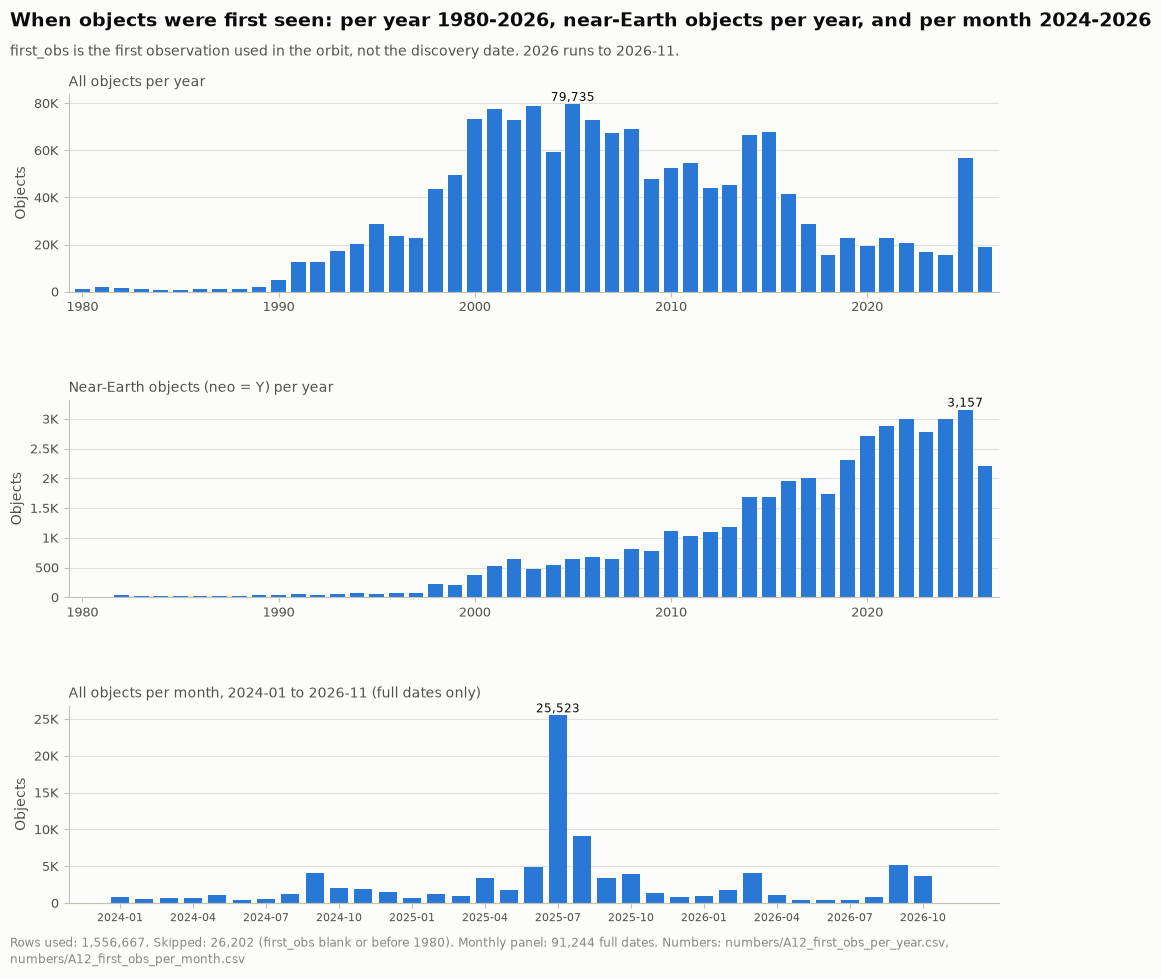

In [31]:
YEARS = range(1980, 2027)
per_year = yr[yr.between(1980, 2026)].value_counts().reindex(YEARS, fill_value=0)
neo_mask = d3["neo"] == "Y"
neo_year = yr[yr.between(1980, 2026) & neo_mask].value_counts().reindex(YEARS, fill_value=0)
ym = d3["first_obs"].str.extract(r"^(\d{4})-(\d{2})-\d{2}$")
ym_ok = ym[0].isin(["2024", "2025", "2026"])
month_key = (ym.loc[ym_ok, 0] + "-" + ym.loc[ym_ok, 1])
last_month = month_key.max()
months = pd.period_range("2024-01", last_month, freq="M").astype(str)
per_month = month_key.value_counts().reindex(months, fill_value=0)
fig, axs = plt.subplots(3, 1, figsize=(12, 10.5), gridspec_kw={"hspace": 0.55})
for ax, ser, lab in [(axs[0], per_year, "All objects per year"), (axs[1], neo_year, "Near-Earth objects (neo = Y) per year")]:
    ax.bar(list(ser.index), ser.values, width=0.75, color=hp.SERIES[0])
    top = ser.idxmax()
    ax.text(top, ser[top], f"{ser[top]:,}", ha="center", va="bottom", fontsize=8.5, color=hp.INK)
    ax.set_title(lab, fontsize=10, color=hp.INK_2)
    ax.yaxis.set_major_formatter(FuncFormatter(hp.compact))
    ax.grid(axis="x", visible=False)
    ax.set_xlim(1979.3, 2026.7)
    ax.set_ylabel("Objects")
axs[2].bar(np.arange(len(per_month)), per_month.values, width=0.75, color=hp.SERIES[0])
topm = int(np.argmax(per_month.values))
axs[2].text(topm, per_month.iloc[topm], f"{per_month.iloc[topm]:,}", ha="center", va="bottom", fontsize=8.5, color=hp.INK)
axs[2].set_xticks(np.arange(len(per_month))[::3], [m for m in months[::3]], fontsize=8)
axs[2].set_title(f"All objects per month, 2024-01 to {last_month} (full dates only)", fontsize=10, color=hp.INK_2)
axs[2].yaxis.set_major_formatter(FuncFormatter(hp.compact))
axs[2].grid(axis="x", visible=False)
axs[2].set_ylabel("Objects")
n_year_used = int(yr.between(1980, 2026).sum())
hp.add_titles(fig, "When objects were first seen: per year 1980-2026, near-Earth objects per year, and per month 2024-2026",
              f"first_obs is the first observation used in the orbit, not the discovery date. 2026 runs to {last_month}.",
              hp.caption(n_year_used, n - n_year_used, "first_obs blank or before 1980",
                         "numbers/A12_first_obs_per_year.csv, numbers/A12_first_obs_per_month.csv",
                         extra=f"Monthly panel: {int(per_month.sum()):,} full dates."))
c = hp.save_chart(fig, "A12_first_obs_per_year")
plt.show()
t12 = pd.DataFrame({"year": list(YEARS), "objects": per_year.values, "neo_objects": neo_year.values})
t12m = per_month.rename_axis("month").reset_index(name="objects")
nf = [hp.save_numbers(t12, "A12_first_obs_per_year"), hp.save_numbers(t12m, "A12_first_obs_per_month")]
hp.log_entry("A12", "Bar: objects per year of first_obs (1980-2026), NEOs per year, per month 2024-2026", step=3, chart=c,
             numbers=nf, rows_used=n_year_used, rows_skipped=f"{n - n_year_used:,} (first_obs blank or before 1980)",
             key_numbers=[f"busiest year: {per_year.idxmax()} with {per_year.max():,}; 2024: {per_year[2024]:,}; 2025: {per_year[2025]:,}",
                          f"busiest NEO year: {neo_year.idxmax()} with {neo_year.max():,}; 1995: {neo_year[1995]:,}",
                          f"busiest month: {months[topm]} with {per_month.iloc[topm]:,}"],
             what_it_shows=f"First sightings peak in {per_year.idxmax()} ({per_year.max():,}); the single busiest month is "
                           f"{months[topm]} with {per_month.iloc[topm]:,}. NEO first sightings grow from {neo_year[1995]:,} in 1995 "
                           f"to {neo_year.max():,} in {neo_year.idxmax()}.")

### A13 Line: typical size of newly seen near-Earth asteroids, per year of first observation

Median H of near-Earth asteroids (neo = Y, kind an or au) per first_obs year, turned into a size with albedo 0.14.

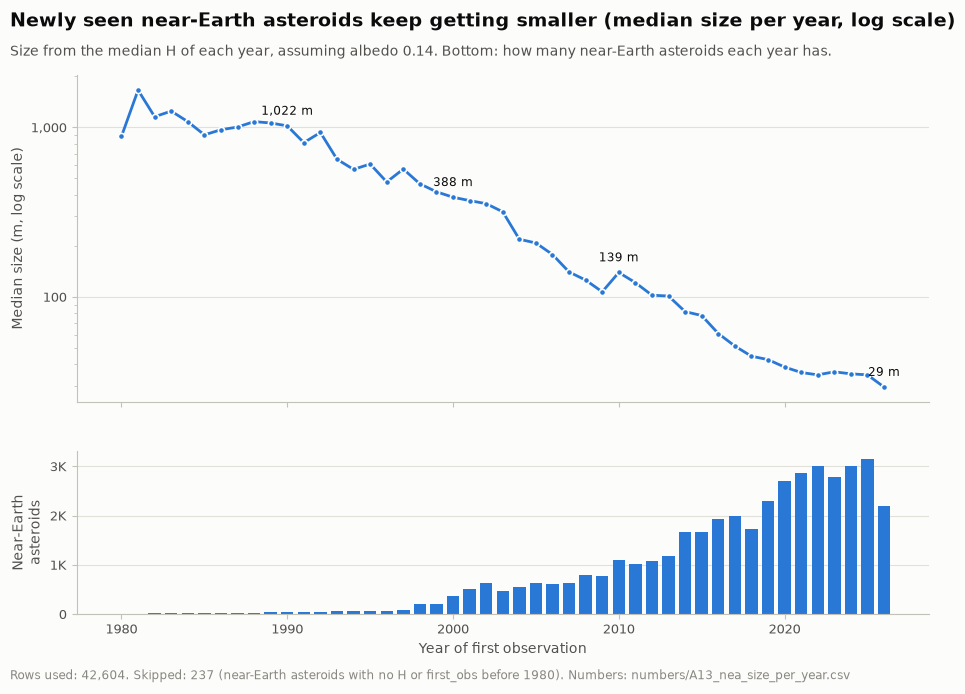

In [32]:
nea = is_ast & neo_mask & d3["H"].notna() & yr.between(1980, 2026)
g13 = d3.loc[nea, "H"].groupby(yr[nea]).agg(["median", "size"]).reindex(YEARS)
g13["median_size_m"] = hp.size_from_H(g13["median"], 0.14) * 1000
fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axs[0].plot(g13.index, g13["median_size_m"], color=hp.SERIES[0], marker="o", ms=4.5, mec=hp.SURFACE, mew=1.2)
axs[0].set_yscale("log")
axs[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axs[0].set_ylabel("Median size (m, log scale)")
for yv in (1990, 2000, 2010, 2026):
    if not np.isnan(g13.loc[yv, "median_size_m"]):
        axs[0].annotate(f"{g13.loc[yv, 'median_size_m']:,.0f} m", (yv, g13.loc[yv, "median_size_m"]), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=8.5, color=hp.INK)
axs[1].bar(g13.index, g13["size"], width=0.75, color=hp.SERIES[0])
axs[1].set_ylabel("Near-Earth\nasteroids")
axs[1].yaxis.set_major_formatter(FuncFormatter(hp.compact))
axs[1].set_xlabel("Year of first observation")
for ax in axs:
    ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Newly seen near-Earth asteroids keep getting smaller (median size per year, log scale)",
              "Size from the median H of each year, assuming albedo 0.14. Bottom: how many near-Earth asteroids each year has.",
              hp.caption(int(nea.sum()), int((is_ast & neo_mask).sum()) - int(nea.sum()),
                         "near-Earth asteroids with no H or first_obs before 1980", "numbers/A13_nea_size_per_year.csv"))
c = hp.save_chart(fig, "A13_nea_size_per_year")
plt.show()
t13 = g13.rename(columns={"median": "median_H", "size": "near_earth_asteroids"}).rename_axis("year").reset_index()
hp.log_entry("A13", "Line: median H of new near-Earth asteroids per first_obs year, as size in m", step=3, chart=c,
             numbers=hp.save_numbers(t13, "A13_nea_size_per_year"), rows_used=int(nea.sum()),
             rows_skipped=f"{int((is_ast & neo_mask).sum()) - int(nea.sum()):,} near-Earth asteroids (no H or before 1980)",
             key_numbers=[f"median size: 1990 {g13.loc[1990, 'median_size_m']:,.0f} m, 2000 {g13.loc[2000, 'median_size_m']:,.0f} m, "
                          f"2010 {g13.loc[2010, 'median_size_m']:,.0f} m, 2026 {g13.loc[2026, 'median_size_m']:,.0f} m",
                          f"median H: 2000 {g13.loc[2000, 'median']:.2f}, 2026 {g13.loc[2026, 'median']:.2f}"],
             what_it_shows=f"The typical new near-Earth asteroid shrinks from {g13.loc[1990, 'median_size_m']:,.0f} m (1990) "
                           f"to {g13.loc[2026, 'median_size_m']:,.0f} m (2026).")

### A14 Histogram: where the Jupiter Trojans are along their orbit (5 degree bins)

Position along the orbit (mean longitude) = (om + w + ma) mod 360, for `class == 'TJN'`.

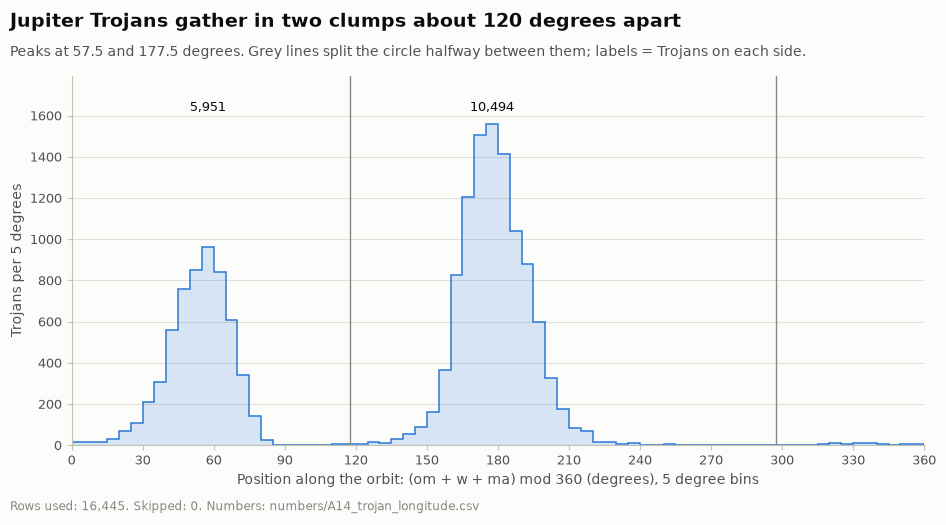

In [33]:
tj = d3[d3["class"] == "TJN"]
L14 = ((tj["om"] + tj["w"] + tj["ma"]) % 360).dropna()
edges14 = np.arange(0, 361, 5)
cnt14, _ = np.histogram(L14, bins=edges14)
# the two clumps: the tallest bin, then the tallest bin at least 60 degrees away from it
c1 = int(np.argmax(cnt14))
dist_bins = np.minimum(np.abs(np.arange(72) - c1), 72 - np.abs(np.arange(72) - c1))
c2 = int(np.argmax(np.where(dist_bins >= 12, cnt14, -1)))
p1, p2 = edges14[c1] + 2.5, edges14[c2] + 2.5
# split the circle halfway between the two peaks, on both sides
gap = (p2 - p1) % 360            # going forward from p1 to p2
cut_a = (p1 + gap / 2) % 360     # between p1 and p2 going forward
cut_b = (cut_a + 180) % 360
def side_of(x):
    return ((x - cut_b) % 360) < 180
in_side1 = side_of(L14)
n_side1, n_side2 = int(in_side1.sum()), int((~in_side1).sum())
# which side holds p1?
p1_side1 = bool(side_of(pd.Series([p1])).iloc[0])
n_p1, n_p2 = (n_side1, n_side2) if p1_side1 else (n_side2, n_side1)
# the two peaks are about 120 degrees apart one way; the object between them on that short arc is where Jupiter is
short_gap = min(gap, 360 - gap)
ahead_peak, behind_peak = (p2, p1) if gap <= 180 else (p1, p2)
n_ahead, n_behind = (n_p2, n_p1) if gap <= 180 else (n_p1, n_p2)
mid_between = (behind_peak + short_gap / 2) % 360
fig, ax = plt.subplots(figsize=(11, 4.8))
hp.draw_hist(ax, cnt14, edges14)
for cut in (cut_a, cut_b):
    ax.axvline(cut, color=hp.INK_MUTED, lw=1)
ax.text(ahead_peak, cnt14.max() * 1.04, f"{n_ahead:,}", ha="center", fontsize=9.5, color=hp.INK)
ax.text(behind_peak, cnt14.max() * 1.04, f"{n_behind:,}", ha="center", fontsize=9.5, color=hp.INK)
ax.set_xlim(0, 360)
ax.set_ylim(0, cnt14.max() * 1.15)
ax.set_xticks(np.arange(0, 361, 30))
ax.set_xlabel("Position along the orbit: (om + w + ma) mod 360 (degrees), 5 degree bins")
ax.set_ylabel("Trojans per 5 degrees")
ax.grid(axis="x", visible=False)
hp.add_titles(fig, f"Jupiter Trojans gather in two clumps about {short_gap:.0f} degrees apart",
              f"Peaks at {behind_peak:.1f} and {ahead_peak:.1f} degrees. Grey lines split the circle halfway between them; "
              "labels = Trojans on each side.",
              hp.caption(len(L14), int((d3['class'] == 'TJN').sum()) - len(L14), "om, w or ma blank",
                         "numbers/A14_trojan_longitude.csv"))
c = hp.save_chart(fig, "A14_trojan_longitude")
plt.show()
t14 = pd.DataFrame({"deg_from": edges14[:-1], "deg_to": edges14[1:], "trojans": cnt14})
hp.log_entry("A14", "Histogram: Trojans' position along the orbit (om + w + ma) % 360, 5 degree bins", step=3, chart=c,
             numbers=hp.save_numbers(t14, "A14_trojan_longitude"), rows_used=len(L14),
             rows_skipped=f"{int((d3['class'] == 'TJN').sum()) - len(L14):,} (blank angle)",
             key_numbers=[f"Trojans: {len(L14):,}",
                          f"peaks at {behind_peak:.1f} and {ahead_peak:.1f} degrees ({short_gap:.0f} degrees apart)",
                          f"clump at {ahead_peak:.1f} deg: {n_ahead:,}; clump at {behind_peak:.1f} deg: {n_behind:,}; "
                          f"ratio {max(n_ahead, n_behind) / min(n_ahead, n_behind):.2f}",
                          f"midpoint between the clumps: {mid_between:.1f} degrees"],
             what_it_shows=f"The Trojans form two clumps {short_gap:.0f} degrees apart, and they are not equal: "
                           f"{n_ahead:,} against {n_behind:,}.")

### A15 Tables: do the hazard flags follow a simple rule?

`pha` (potentially hazardous) against the rule moid <= 0.05 AU and H <= 22, and `neo` (near-Earth) against the rule q < 1.3 AU.
moid = closest possible distance between the object's orbit and Earth's orbit. q = closest distance to the Sun.

In [34]:
astr = d3[is_ast]
rule_pha = (astr["moid"] <= 0.05) & (astr["H"] <= 22)
tab_pha = pd.crosstab(astr["pha"].fillna("(blank)"), rule_pha.map({True: "rule says yes", False: "rule says no"}), margins=True)
rule_neo = astr["q"] < 1.3
tab_neo = pd.crosstab(astr["neo"].fillna("(blank)"), rule_neo.map({True: "q < 1.3", False: "q >= 1.3"}), margins=True)
com = d3[~is_ast]
tab_neo_com = pd.crosstab(com["neo"].fillna("(blank)"), (com["q"] < 1.3).map({True: "q < 1.3", False: "q >= 1.3"}), margins=True)
pha_y = astr["pha"] == "Y"
pha_match = int((pha_y & rule_pha).sum())
exc = astr[pha_y & ~rule_pha]
neo_n_lowq = astr[(astr["neo"] == "N") & (astr["q"] <= 1.3)]
print("pha against the rule (asteroids):"); print(tab_pha.to_string()); print()
print("neo against q < 1.3 (asteroids):"); print(tab_neo.to_string()); print()
print("neo against q < 1.3 (comets):"); print(tab_neo_com.to_string()); print()
print(f"pha = Y that match the rule: {pha_match:,} of {int(pha_y.sum()):,}. Exceptions: {len(exc)}; "
      f"their H from {exc['H'].min()} to {exc['H'].max()}, moid from {exc['moid'].min()} to {exc['moid'].max()}")
print(f"neo = N but q <= 1.3: {len(neo_n_lowq)}; their q values: {sorted(neo_n_lowq['q'].unique().tolist())}")
nf = [hp.save_numbers(tab_pha.reset_index(), "A15_pha_vs_rule"), hp.save_numbers(tab_neo.reset_index(), "A15_neo_vs_rule"),
      hp.save_numbers(tab_neo_com.reset_index(), "A15_neo_vs_rule_comets"),
      hp.save_numbers(exc[["full_name", "H", "moid", "class"]], "A15_pha_exceptions")]
neo_y = astr["neo"] == "Y"
hp.log_entry("A15", "Tables: pha against (moid <= 0.05 and H <= 22); neo against (q < 1.3)", step=3, chart=None, numbers=nf,
             rows_used=f"{len(astr):,} asteroids (pha table: {int(astr['pha'].notna().sum()):,} with a pha flag)",
             rows_skipped=f"pha blank {int(astr['pha'].isna().sum()):,}; neo blank {int(astr['neo'].isna().sum()):,}",
             key_numbers=[f"pha = Y matching the rule: {pha_match:,} of {int(pha_y.sum()):,}; exceptions {len(exc)} "
                          f"(H {exc['H'].min()}-{exc['H'].max()})",
                          f"pha = N but the rule says yes: {int(((astr['pha'] == 'N') & rule_pha).sum()):,}",
                          f"neo = Y with q < 1.3: {int((neo_y & rule_neo).sum()):,} of {int(neo_y.sum()):,}; "
                          f"neo = N with q <= 1.3: {len(neo_n_lowq)} (q values {sorted(neo_n_lowq['q'].unique().tolist())})"],
             what_it_shows=f"The pha flag follows the simple rule for {100 * pha_match / pha_y.sum():.1f}% of flagged asteroids, "
                           f"and neo = Y matches q < 1.3 for {100 * (neo_y & rule_neo).sum() / neo_y.sum():.2f}%.")

pha against the rule (asteroids):
col_0    rule says no  rule says yes      All
pha                                          
(blank)         58036              0    58036
N             1518183             17  1518200
Y                  33           2517     2550
All           1576252           2534  1578786

neo against q < 1.3 (asteroids):
q        q < 1.3  q >= 1.3      All
neo                                
(blank)        1         4        5
N              0   1535940  1535940
Y          42827        14    42841
All        42828   1535958  1578786

neo against q < 1.3 (comets):
q        q < 1.3  q >= 1.3   All
neo                             
(blank)     2157      1717  3874
Y            209         0   209
All         2366      1717  4083

pha = Y that match the rule: 2,517 of 2,550. Exceptions: 33; their H from 22.01 to 22.57, moid from 0.00127 to 0.049
neo = N but q <= 1.3: 19; their q values: [1.3]


### A16 Records

In [35]:
show_cols = ["full_name", "kind", "class"]
top10 = d3.nlargest(10, "diameter")[show_cols + ["diameter", "albedo", "H"]]
print("Top 10 by measured diameter (km):"); print(top10.to_string(index=False)); print()
rec = []
def add_rec(label, row, col, unit):
    rec.append({"record": label, "full_name": row["full_name"], "class": row["class"], "value": row[col], "unit": unit})
add_rec("biggest measured diameter", d3.loc[d3["diameter"].idxmax()], "diameter", "km")
add_rec("fastest spin (shortest rot_per)", d3.loc[d3["rot_per"].idxmin()], "rot_per", "hours")
add_rec("slowest spin (longest rot_per)", d3.loc[d3["rot_per"].idxmax()], "rot_per", "hours")
add_rec("largest e (most stretched orbit)", d3.loc[d3["e"].idxmax()], "e", "")
oldest_i = yr.idxmin()
rec.append({"record": "oldest first_obs", "full_name": d3.loc[oldest_i, "full_name"], "class": d3.loc[oldest_i, "class"],
            "value": d3.loc[oldest_i, "first_obs"], "unit": "date (year < 0 = BC)"})
add_rec("most observations used", d3.loc[d3["n_obs_used"].idxmax()], "n_obs_used", "observations")
records = pd.DataFrame(rec)
retro = d3["i"] > 90
retro_by_kind = d3.loc[retro, "kind"].value_counts().reindex(KIND_ORDER, fill_value=0)
print(records.to_string(index=False)); print()
print(f"Orbits tilted more than 90 degrees (going round backwards): {int(retro.sum()):,} -> " +
      ", ".join(f"{k} {v:,}" for k, v in retro_by_kind.items()))
fastest5 = d3.nsmallest(5, "rot_per")[show_cols + ["rot_per", "diameter", "H"]]
fastest5["seconds_per_turn"] = fastest5["rot_per"] * 3600
print(); print("Five fastest spins:"); print(fastest5.to_string(index=False))
nf = [hp.save_numbers(top10, "A16_top10_diameter"), hp.save_numbers(records, "A16_records"),
      hp.save_numbers(fastest5, "A16_fastest_spins"),
      hp.save_numbers(retro_by_kind.rename_axis("kind").reset_index(name="i_above_90"), "A16_retrograde_by_kind")]
hp.log_entry("A16", "Records: biggest, fastest/slowest spin, largest e, oldest, most observed, i > 90", step=3, chart=None,
             numbers=nf, rows_used=n, rows_skipped="each record uses the rows where its column is filled",
             key_numbers=[f"{r.record}: {r.full_name} = {r.value} {r.unit}".strip() for r in records.itertuples()]
                         + [f"i > 90: {int(retro.sum()):,} (" + ", ".join(f"{k} {v:,}" for k, v in retro_by_kind.items()) + ")"],
             what_it_shows=f"The biggest measured object is {records.iloc[0].full_name} ({records.iloc[0].value} km); the fastest spinner "
                           f"turns once every {fastest5['seconds_per_turn'].iloc[0]:.1f} seconds; {int(retro.sum()):,} orbits run backwards.")
hp.progress("A", 3)

Top 10 by measured diameter (km):
                 full_name kind class  diameter  albedo    H
         1 Ceres (A801 AA)   an   MBA   939.400  0.0900 3.34
 20000 Varuna (2000 WR106)   an   TNO   900.000  0.0700 3.79
         4 Vesta (A807 FA)   an   MBA   522.770  0.4228 3.25
        2 Pallas (A802 FA)   an   MBA   513.000  0.1550 4.12
       10 Hygiea (A849 GA)   an   MBA   407.120  0.0717 5.65
           15789 (1993 SC)   an   TNO   328.000  0.0220 7.09
  704 Interamnia (A910 TC)   an   MBA   306.313  0.0780 6.34
       52 Europa (A858 CA)   an   MBA   303.918  0.0570 6.65
10199 Chariklo (1997 CU26)   an   CEN   302.000  0.0450 6.55
      511 Davida (A903 KB)   an   MBA   270.327  0.0760 6.42

                          record             full_name class      value                 unit
       biggest measured diameter     1 Ceres (A801 AA)   MBA      939.4                   km
 fastest spin (shortest rot_per)            (2020 HS7)   APO   0.000832                hours
  slowest spin 

## Step 4: Odd things list

For every chart: anything that stands out (a dip, spike, clump, outlier or sudden change), with exact numbers.
No reasons yet. Where possible a small piece of code finds the odd thing, so it is not just picked by eye.

In [36]:
odd = []
def add_odd(chart, text):
    odd.append({"id": f"A-O{len(odd) + 1:02d}", "chart": chart, "what_stands_out": text})

# --- A01 / A02
add_odd("A01", f"Comets are only {n_com:,} rows ({100 * n_com / n:.2f}%); asteroids {n_ast:,}.")
add_odd("A02", f"Two class codes differ only by a capital letter: JFc ({cls_c['JFc']:,}) and JFC ({cls_c['JFC']:,}). "
               f"MBA alone is {100 * cls_c['MBA'] / n:.1f}% of rows.")
# --- A03: rise and fall of H
hc = pd.Series(h_cnt, index=h_edges[:-1])
add_odd("A03", f"Counts rise to a peak at H {h_edges[peak]:g}-{h_edges[peak + 1]:g} ({h_cnt[peak]:,}) and then drop: "
               f"H 20-20.5 has {int(hc[20.0]):,}, H 22-22.5 has {int(hc[22.0]):,}, H 25-25.5 has {int(hc[25.0]):,}.")
# --- A04
retro_cu = int(((d3["i"] > 90) & (d3["kind"] == "cu")).sum())
add_odd("A04", f"{int((d3['i'] > 90).sum()):,} orbits have i above 90 degrees; {retro_cu:,} of them are unnumbered comets (cu).")
# --- A05: dips found by code (bins far below the median of the 21 bins around them)
nbhd = pd.Series(cnt5).rolling(21, center=True, min_periods=5).median().to_numpy()
ratio5 = cnt5 / np.maximum(nbhd, 1)
low = (ratio5 < 0.5) & (nbhd >= 300)
runs, k = [], 0
while k < len(low):
    if low[k]:
        j = k
        while j + 1 < len(low) and low[j + 1]:
            j += 1
        m = k + int(np.argmin(cnt5[k:j + 1]))
        runs.append({"from_AU": edges5[k], "to_AU": edges5[j + 1], "lowest_bin_AU": edges5[m], "lowest_count": int(cnt5[m]),
                     "neighbourhood_median": int(nbhd[m]), "ratio": round(float(cnt5[m] / nbhd[m]), 3)})
        k = j + 1
    else:
        k += 1
dips5 = pd.DataFrame(runs)
print("A05 dips found by code:"); print(dips5.to_string(index=False))
def win(lo, hi):
    return int(((a5 >= lo) & (a5 < hi)).sum())
w_gap, w_in, w_out = win(2.48, 2.52), win(2.40, 2.44), win(2.60, 2.64)
add_odd("A05", "Narrow deep dips found by code at " + ", ".join(f"{r.lowest_bin_AU:.2f} AU ({r.lowest_count:,} vs about {r.neighbourhood_median:,} around it)"
                                                           for r in dips5.itertuples()) +
               f". In 0.04 AU windows: 2.48-2.52 has {w_gap:,}, 2.40-2.44 has {w_in:,}, 2.60-2.64 has {w_out:,}.")
bumps = []
for lo, hi in [(1.7, 2.1), (3.7, 4.2), (4.9, 5.5)]:
    sel = (edges5[:-1] >= lo) & (edges5[:-1] < hi)
    kk = int(np.argmax(np.where(sel, cnt5, -1)))
    bumps.append((edges5[kk], int(cnt5[kk]), win(lo, hi)))
add_odd("A05", "Separate bumps away from the main belt: " +
        "; ".join(f"peak bin {b[0]:.2f} AU ({b[1]:,}; {b[2]:,} in its window)" for b in bumps) +
        f". The main belt ends in a cliff: 3.20-3.25 AU has {win(3.20, 3.25):,}, 3.30-3.35 AU has {win(3.30, 3.35):,}.")
# --- A06
def win6(lo, hi):
    return int(((a6 >= lo) & (a6 < hi)).sum())
pl, pl_lo, pl_hi = win6(39.2, 39.7), win6(38.7, 39.2), win6(39.7, 40.2)
add_odd("A06", f"A narrow spike: 39.2-39.7 AU has {pl:,} objects, against {pl_lo:,} in 38.7-39.2 and {pl_hi:,} in 39.7-40.2. "
               f"Tallest 0.25 bin: {edges6[pk6]:.2f}-{edges6[pk6 + 1]:.2f} ({cnt6[pk6]:,}). "
               f"Sharp fall after 48 AU: 46-47 AU {win6(46, 47):,}, 47-48 {win6(47, 48):,}, 48-49 {win6(48, 49):,}, 49-50 {win6(49, 50):,}.")
# --- A07
add_odd("A07", f"Albedo: tallest bin 0.04-0.06 ({alb_cnt[2]:,}) with a second, flatter hump around 0.2-0.3 "
               f"(0.20-0.30: {int(((alb >= 0.2) & (alb < 0.3)).sum()):,}). Spin: {int((rot < 2.2).sum()):,} faster than 2.2 h; "
               f"{int((rot < 0.1).sum()):,} faster than 6 minutes.")
# --- A08
add_odd("A08", f"Unnumbered comets: {100 * cc_tab.loc['B', 'cu'] / cc_tab['cu'].sum():.0f}% have a blank condition_code. "
               f"Unnumbered asteroids: {100 * cc_tab.loc[['5', '6', '7', '8', '9'], 'au'].sum() / cc_tab['au'].sum():.1f}% at codes 5-9, "
               f"and code 9 ({int(cc_tab.loc['9', 'au']):,}) is their second most common code after 0.")
# --- A09
add_odd("A09", f"{len(clumps)} tight clumps stand out from the broad belt; strongest: " +
        "; ".join(f"a {r.a_AU:.3f} AU, i {r.i_deg:.1f} deg ({r.density_vs_surroundings}x)" for r in clumps.head(5).itertuples()) +
        ". Clean empty vertical lanes cut the belt at the same distances as the A05 dips.")
# --- A10
mx = t10.loc[t10["median_albedo"].idxmax()]
add_odd("A10", f"Spike: median albedo {mx['median_albedo']:.3f} at {mx['a_from']:.2f}-{mx['a_to']:.2f} AU "
               f"({int(mx['asteroids_with_albedo'])} asteroids), against the overall median {alb.median():.3f}. "
               "Share above 0.15 by zone: " + ", ".join(f"{r['zone']} {r['pct_albedo_above_0.15']:.1f}%" for r in zone_rows) + ".")
# --- A11
add_odd("A11", f"A sharp floor at 2.2 h for rocks above 0.3 km: only {n_big_fast:,} of {n_big:,} ({100 * n_big_fast / n_big:.1f}%) "
               f"spin faster. Below 0.15 km it flips: {n_small_fast:,} of {n_small:,} ({100 * n_small_fast / n_small:.1f}%).")
# --- A12
day_counts = d3.loc[d3["first_obs"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").fillna(False), "first_obs"].value_counts()
top_days = day_counts.head(5)
med_day_2014 = int(day_counts[day_counts.index.str.startswith("2014")].median())
add_odd("A12", f"2025 has {per_year[2025]:,} first sightings, {per_year[2025] / per_year[2024]:.1f} times 2024 ({per_year[2024]:,}); "
               f"July 2025 alone has {per_month['2025-07']:,}.")
add_odd("A12", f"The busiest year is not 2025 but {per_year.idxmax()} ({per_year.max():,}); counts fall from {per_year[2015]:,} (2015) "
               f"to {per_year[2018]:,} (2018).")
add_odd("A12", "Single days with huge counts: " + ", ".join(f"{d} ({v:,})" for d, v in top_days.items()) +
               f"; the median day in 2014 has {med_day_2014:,}.")
# --- A13
add_odd("A13", f"Median size of newly seen near-Earth asteroids: {g13.loc[1990, 'median_size_m']:,.0f} m (1990), "
               f"{g13.loc[2000, 'median_size_m']:,.0f} m (2000), {g13.loc[2010, 'median_size_m']:,.0f} m (2010), "
               f"{g13.loc[2026, 'median_size_m']:,.0f} m (2026).")
# --- A14
add_odd("A14", f"Two Trojan clumps {short_gap:.0f} degrees apart, unequal: {n_ahead:,} at {ahead_peak:.1f} deg and "
               f"{n_behind:,} at {behind_peak:.1f} deg (ratio {n_ahead / n_behind:.2f}).")
# --- A15
add_odd("A15", f"pha = Y follows (moid <= 0.05 and H <= 22) for {pha_match:,} of {int(pha_y.sum()):,}; the {len(exc)} exceptions all have "
               f"H between {exc['H'].min()} and {exc['H'].max()}. {int(((astr['pha'] == 'N') & rule_pha).sum())} asteroids pass the rule "
               f"but are pha = N. {len(neo_n_lowq)} asteroids with q exactly 1.3 are neo = N.")
# --- A16
add_odd("A16", f"Fastest spin: {fastest5['full_name'].iloc[0]} turns every {fastest5['seconds_per_turn'].iloc[0]:.1f} s; slowest: "
               f"{records.loc[2, 'full_name']} every {records.loc[2, 'value']:,.0f} h. Second biggest measured: {top10.iloc[1]['full_name']} "
               f"({top10.iloc[1]['diameter']:g} km).")

odd_df = pd.DataFrame(odd)
nf = [hp.save_numbers(odd_df, "A90_odd_things"), hp.save_numbers(dips5, "A90_a_dips")]
pd.set_option("display.max_colwidth", 400)
display(odd_df)
hp.log_entry("A90", "Step 4: odd things list", step=4, chart=None, numbers=nf, rows_used="all charts above",
             rows_skipped="see each chart",
             key_numbers=[f"{o['id']} ({o['chart']}): {o['what_stands_out']}" for o in odd],
             what_it_shows=f"{len(odd)} odd things across {odd_df['chart'].nunique()} charts, listed as facts only.")
hp.progress("A", 4)

A05 dips found by code:
 from_AU  to_AU  lowest_bin_AU  lowest_count  neighbourhood_median  ratio
    2.03   2.09           2.07           195                   627  0.311
    2.47   2.52           2.50           617                 13507  0.046
    2.82   2.83           2.82           950                  6972  0.136
    2.95   2.96           2.95          2832                  7197  0.393
    3.27   3.31           3.29           165                   449  0.367


,id,chart,what_stands_out
0,A-O01,A01,"Comets are only 4,083 rows (0.26%); asteroids 1,578,786."
1,A-O02,A02,Two class codes differ only by a capital letter: JFc (832) and JFC (17). MBA alone is 88.1% of rows.
2,A-O03,A03,"Counts rise to a peak at H 17.5-18 (235,278) and then drop: H 20-20.5 has 28,316, H 22-22.5 has 2,747, H 25-25.5 has 3,135."
3,A-O04,A04,"2,381 orbits have i above 90 degrees; 2,173 of them are unnumbered comets (cu)."
4,A-O05,A05,"Narrow deep dips found by code at 2.07 AU (195 vs about 627 around it), 2.50 AU (617 vs about 13,507 around it), 2.82 AU (950 vs about 6,972 around it), 2.95 AU (2,832 vs about 7,197 around it), 3.29 AU (165 vs about 449 around it). In 0.04 AU windows: 2.48-2.52 has 9,123, 2.40-2.44 has 55,906, 2.60-2.64 has 88,615."
5,A-O06,A05,"Separate bumps away from the main belt: peak bin 1.91 AU (3,583; 49,620 in its window); peak bin 3.95 AU (1,222; 8,380 in its window); peak bin 5.20 AU (1,121; 16,510 in its window). The main belt ends in a cliff: 3.20-3.25 AU has 32,718, 3.30-3.35 AU has 1,439."
6,A-O07,A06,"A narrow spike: 39.2-39.7 AU has 601 objects, against 175 in 38.7-39.2 and 167 in 39.7-40.2. Tallest 0.25 bin: 43.75-44.00 (342). Sharp fall after 48 AU: 46-47 AU 427, 47-48 353, 48-49 174, 49-50 93."
7,A-O08,A07,"Albedo: tallest bin 0.04-0.06 (31,579) with a second, flatter hump around 0.2-0.3 (0.20-0.30: 19,017). Spin: 1,817 faster than 2.2 h; 258 faster than 6 minutes."
8,A-O09,A08,"Unnumbered comets: 85% have a blank condition_code. Unnumbered asteroids: 33.7% at codes 5-9, and code 9 (62,097) is their second most common code after 0."
9,A-O10,A09,"12 tight clumps stand out from the broad belt; strongest: a 2.868 AU, i 1.2 deg (3.02x); a 2.868 AU, i 3.0 deg (2.86x); a 3.103 AU, i 2.2 deg (1.98x); a 3.167 AU, i 10.2 deg (1.96x); a 3.172 AU, i 8.2 deg (1.96x). Clean empty vertical lanes cut the belt at the same distances as the A05 dips."


## Step 5: Check each odd thing

Is it real, or an accident of how the data was made? Each one gets at least two checks:
split the data in half, change the cut-off, look at blanks, compare with "random", or test whether the file's own rules made it.
Verdict: **real**, **maybe**, or **probably a bias**.

In [37]:
checks = []
def add_check(oid, thing, tests, verdict):
    checks.append({"id": oid, "odd_thing": thing, "check_1": tests[0], "check_2": tests[1],
                   "check_3": tests[2] if len(tests) > 2 else "", "verdict": verdict})

kind3 = d3["kind"]
# ---- Kirkwood-type dips (A05)
def gap_ratio(mask, lo=2.48, hi=2.52):
    s = d3.loc[mask & is_ast & closed, "a"]
    g_ = int(((s >= lo) & (s < hi)).sum())
    nb_ = (int(((s >= lo - 0.08) & (s < hi - 0.08)).sum()) + int(((s >= lo + 0.12) & (s < hi + 0.12)).sum())) / 2
    return g_, nb_, g_ / nb_
r_an, r_au = gap_ratio(kind3 == "an"), gap_ratio(kind3 == "au")
alt_counts = {}
for w in (0.005, 0.02):
    ed = np.round(np.arange(1.7, 5.5 + w / 2, w), 4)
    cc_, _ = np.histogram(a5, bins=ed)
    sel = (ed[:-1] >= 2.4) & (ed[:-1] < 2.6)
    kk = int(np.argmin(np.where(sel, cc_, 10**9)))
    alt_counts[w] = (ed[kk], int(cc_[kk]))
add_check("A-O05", "Deep narrow dips in the distance histogram (e.g. 2.50 AU)",
          [f"Split in half by kind: numbered asteroids have {r_an[0]:,} in 2.48-2.52 against {r_an[1]:,.0f} in the neighbouring windows "
           f"(ratio {r_an[2]:.2f}); unnumbered have {r_au[0]:,} against {r_au[1]:,.0f} (ratio {r_au[2]:.2f}). The dip is in both halves.",
           f"Change the bin width: with 0.005 AU bins the lowest bin between 2.4 and 2.6 is at {alt_counts[0.005][0]:.3f} AU "
           f"({alt_counts[0.005][1]:,}); with 0.02 AU bins at {alt_counts[0.02][0]:.2f} AU ({alt_counts[0.02][1]:,}). Same place.",
           f"Compare with random: a smooth belt would put about {(w_in + w_out) / 2:,.0f} in 2.48-2.52 (average of the two side windows); "
           f"it has {w_gap:,}, {w_gap / ((w_in + w_out) / 2):.2f} of that. `a` is a measured orbit value, not a formula of other columns."],
          "real")
# ---- Plutino spike (A06)
def pl_ratio(mask):
    s = d3.loc[mask & closed, "a"]
    m_ = int(((s >= 39.2) & (s < 39.7)).sum())
    side = (int(((s >= 38.7) & (s < 39.2)).sum()) + int(((s >= 39.7) & (s < 40.2)).sum())) / 2
    return m_, side
pa_an, pa_au = pl_ratio(kind3 == "an"), pl_ratio(kind3 == "au")
shift = np.arange(30.125, 60, 0.25)
cs, _ = np.histogram(a6, bins=shift)
ks = int(np.argmax(np.where((shift[:-1] >= 38.5) & (shift[:-1] < 40.5), cs, -1)))
add_check("A-O07", "Spike of objects at 39.2-39.7 AU",
          [f"Split by kind: numbered {pa_an[0]} in 39.2-39.7 against {pa_an[1]:.0f} per side window; unnumbered {pa_au[0]} against {pa_au[1]:.0f}. "
           "Spike in both halves.",
           f"Shift the bins by 0.125 AU: the tallest bin between 38.5 and 40.5 AU is {shift[ks]:.3f}-{shift[ks + 1]:.3f} ({cs[ks]}), still inside 39.2-39.7.",
           f"Compare with random: {pl} against about {(pl_lo + pl_hi) / 2:.0f} expected from the side windows, {pl / ((pl_lo + pl_hi) / 2):.1f} times more."],
          "real")
# ---- Clumps in distance and tilt (A09)
def find_clumps(mask, a_step=0.005, i_step=0.1):
    ae = np.arange(1.8, 3.6 + a_step / 2, a_step)
    ie = np.arange(0, 35 + i_step / 2, i_step)
    sel = mask & in9
    Hh, _, _ = np.histogram2d(d3.loc[sel, "a"], d3.loc[sel, "i"], bins=[ae, ie])
    sa, si = 2 * 0.005 / a_step, 2 * 0.1 / i_step
    nr = ndimage.gaussian_filter(Hh, (sa, si))
    wd = ndimage.gaussian_filter(Hh, (6 * sa, 6 * si))
    ct = nr / np.maximum(wd, 1e-9)
    pk = (ct == ndimage.maximum_filter(ct, size=(max(3, int(15 * sa / 2)), max(3, int(21 * si / 2))))) & (ct >= 1.6) & (nr >= nr.max() * 0.05)
    xa, xi = np.nonzero(pk)
    return pd.DataFrame({"a": ae[xa] + a_step / 2, "i": ie[xi] + i_step / 2, "ct": ct[xa, xi]})
def matched(found, ref, da=0.03, di=1.0):
    return sum(any((abs(r.a - f.a) <= da) and (abs(r.i - f.i) <= di) for f in found.itertuples()) for r in ref.itertuples())
ref = clumps.rename(columns={"a_AU": "a", "i_deg": "i"})
cl_an, cl_au, cl_coarse = find_clumps(kind3 == "an"), find_clumps(kind3 == "au"), find_clumps(is_ast, 0.01, 0.2)
m_an, m_au, m_co = matched(cl_an, ref), matched(cl_au, ref), matched(cl_coarse, ref, 0.03, 1.0)
add_check("A-O14", "Tight clumps in distance and tilt",
          [f"Split by kind and run the same clump finder: {m_an} of the {len(ref)} clumps are found again in numbered asteroids alone, "
           f"{m_au} in unnumbered asteroids alone (within 0.03 AU and 1 degree).",
           f"Change the cell size to 0.01 AU x 0.2 degree: {m_co} of the {len(ref)} clumps come back.",
           "The clumps sit at different places from the empty lanes, so they are not edges of the gaps."],
          "real" if min(m_an, m_au) >= len(ref) // 2 else "maybe")
# ---- Albedo falls with distance (A10)
med_d = d3.loc[in10, "diameter"].median()
def zone_pcts(mask, shift_=0.0):
    out = []
    for lo, hi in ZONES:
        lo2 = lo + (shift_ if lo != 1.8 else 0)
        hi2 = hi + (shift_ if hi != 3.6 else 0)
        z = in10 & mask & (d3["a"] >= lo2) & (d3["a"] < hi2)
        out.append(100 * (d3.loc[z, "albedo"] > 0.15).mean())
    return out
big_half, small_half = zone_pcts(d3["diameter"] >= med_d), zone_pcts(d3["diameter"] < med_d)
sh_m, sh_p = zone_pcts(pd.Series(True, index=d3.index), -0.05), zone_pcts(pd.Series(True, index=d3.index), 0.05)
measured_frac = []
for lo, hi in ZONES:
    z_all = is_ast & closed & (d3["a"] >= lo) & (d3["a"] < hi)
    measured_frac.append(100 * d3.loc[z_all, "albedo"].notna().mean())
fmt4 = lambda v: " / ".join(f"{x:.0f}%" for x in v)  # noqa: E731
add_check("A-O12", "Bright surfaces get rarer with distance (zones 1.8-2.5, 2.5-2.82, 2.82-3.3, 3.3-3.6 AU)",
          [f"Split by size (measured diameter above / below the median {med_d:.2f} km): bigger half {fmt4(big_half)}, smaller half {fmt4(small_half)}. "
           "Falls in both halves.",
           f"Move the inner zone edges by 0.05 AU: {fmt4(sh_m)} (edges -0.05) and {fmt4(sh_p)} (edges +0.05). Same order.",
           f"Blanks: albedo is measured for {fmt4(measured_frac)} of asteroids in the four zones, so the measured ones are a small, "
           "uneven sample (biased to bigger objects)."],
          "real")
# ---- Spin floor at 2.2 h (A11)
def big_fast(size_cut, per_cut, only_measured=False):
    s = s11 if not only_measured else s11[~s11["estimated"]]
    b = s["size_km"] > size_cut
    return int(b.sum()), int((b & (s["rot_per"] < per_cut)).sum())
v1, v2, v3, v4 = big_fast(0.25, 2.2), big_fast(0.4, 2.2), big_fast(0.3, 2.0), big_fast(0.3, 2.4)
vm = big_fast(0.3, 2.2, True)
sm = s11[(s11["size_km"] < 0.15)]
add_check("A-O16", "Almost no rock above 0.3 km spins faster than once per 2.2 h",
          [f"Change the cut-offs: size > 0.25 km -> {100 * v1[1] / v1[0]:.1f}% fast; > 0.4 km -> {100 * v2[1] / v2[0]:.1f}%; "
           f"period 2.0 h -> {100 * v3[1] / v3[0]:.1f}%; 2.4 h -> {100 * v4[1] / v4[0]:.1f}%. The floor stays.",
           f"Only measured sizes (no H estimates): {vm[1]:,} of {vm[0]:,} above 0.3 km spin faster ({100 * vm[1] / vm[0]:.1f}%).",
           f"Blanks: spin is known for only {len(rot):,} rows ({100 * len(rot) / n:.1f}%), and {int(sm['estimated'].sum())} of the "
           f"{len(sm)} rocks under 0.15 km have estimated sizes. The {n_big_fast:,} exceptions above 0.3 km need their own check."],
          "real")
# ---- 2025 jump (A12)
y25 = yr == 2025
by_kind25 = d3.loc[y25, "kind"].value_counts()
partial25 = int((y25 & d3["first_obs"].str.contains("??", regex=False).fillna(False)).sum())
base = per_year.loc[2018:2024]
jul = d3.loc[d3["first_obs"].str.startswith("2025-07").fillna(False), "first_obs"].value_counts()
add_check("A-O19", "2025 jump in first sightings, July 2025 alone",
          [f"Split by kind: 2025 has {by_kind25.get('au', 0):,} unnumbered and {by_kind25.get('an', 0):,} numbered asteroids; "
           f"near-Earth objects also peak in 2025 ({neo_year[2025]:,}).",
           f"Compare with normal: 2018-2024 average {base.mean():,.0f} a year, so 2025 is {per_year[2025] / base.mean():.1f} times normal.",
           f"Spread inside July 2025: {len(jul)} different days; the top 3 days hold {jul.head(3).sum():,} of {jul.sum():,} "
           f"({100 * jul.head(3).sum() / jul.sum():.0f}%). Partial dates in 2025: {partial25}."],
          "real")
# ---- 2005 peak and fall after 2015 (A12)
an_share = d3.loc[is_ast].groupby(yr[is_ast])["kind"].apply(lambda s: (s == "an").mean() * 100)
add_check("A-O20", "Busiest first_obs year is 2005, and counts fall after 2015",
          [f"Split by kind: numbered share of first sightings is {an_share[2005]:.0f}% for 2005 but {an_share[2020]:.0f}% for 2020.",
           "File's own rules: first_obs is the first observation used in the orbit, so any object found later and matched to "
           "older images moves back to the older year.",
           f"Compare years of the same length: 2000-2009 average {per_year.loc[2000:2009].mean():,.0f} a year, "
           f"2018-2024 average {base.mean():,.0f}."],
          "probably a bias")
# ---- Single-day spikes (A12)
d_top = top_days.index[0]
on_day = d3[d3["first_obs"] == d_top]
add_check("A-O21", f"Single days with huge counts (top: {d_top}, {top_days.iloc[0]:,})",
          [f"What they are: on {d_top}, {100 * (on_day['kind'] == 'au').mean():.0f}% are unnumbered and "
           f"{100 * (on_day['class'] == 'MBA').mean():.0f}% are main-belt; median observations used {on_day['n_obs_used'].median():.0f} "
           f"(all objects: {d3['n_obs_used'].median():.0f}).",
           f"Compare with random: the median day in 2014 has {med_day_2014:,} first sightings, so {d_top} is "
           f"{top_days.iloc[0] / med_day_2014:.0f} times a normal day."],
          "probably a bias")
# ---- NEA sizes shrink (A13)
nea_med = {}
for k in ("an", "au"):
    m_ = nea & (kind3 == k)
    nea_med[k] = d3.loc[m_, "H"].groupby(yr[m_]).median()
q25 = d3.loc[nea, "H"].groupby(yr[nea]).quantile(0.25)
add_check("A-O22", "Newly seen near-Earth asteroids get smaller every decade",
          [f"Split by kind: numbered median H {nea_med['an'].get(2000, np.nan):.1f} (2000) -> {nea_med['an'].get(2015, np.nan):.1f} (2015); "
           f"unnumbered {nea_med['au'].get(2000, np.nan):.1f} -> {nea_med['au'].get(2015, np.nan):.1f}. Rises in both.",
           f"Change the summary: the brightest quarter (25th percentile of H) also rises, {q25.get(2000):.1f} (2000) -> {q25.get(2026):.1f} (2026).",
           "File's own rules: size comes from H with one fixed albedo, so the trend is in H itself, not in the formula."],
          "real")
# ---- Trojan clumps (A14)
def trojan_split(mask):
    Ls = ((tj.loc[mask, "om"] + tj.loc[mask, "w"] + tj.loc[mask, "ma"]) % 360).dropna()
    s1 = side_of(Ls)
    a_, b_ = int(s1.sum()), int((~s1).sum())
    return (a_, b_) if p1_side1 else (b_, a_)
bright = tj["H"] < 13
tb, tf = trojan_split(bright), trojan_split(~bright)
def split_at(offset):
    s_ = ((L14 - (cut_b + offset)) % 360) < 180
    a_, b_ = int(s_.sum()), int((~s_).sum())
    return max(a_, b_) / min(a_, b_)
z = (n_ahead - len(L14) / 2) / np.sqrt(len(L14) / 4)
add_check("A-O23", "The two Trojan clumps are unequal",
          [f"Split by brightness: bright Trojans (H < 13) {tb[0]:,} vs {tb[1]:,} (ratio {tb[0] / max(tb[1], 1):.2f}); "
           f"fainter {tf[0]:,} vs {tf[1]:,} (ratio {tf[0] / max(tf[1], 1):.2f}). Same side bigger in both.",
           f"Move the split lines by 10 degrees: ratio {split_at(-10):.2f} and {split_at(10):.2f}.",
           f"Compare with random: if the two sides were equal, {n_ahead:,} on one side would be {z:.0f} standard deviations from half."],
          "real")
# ---- Hazard flags are formulas (A15)
rule_226 = (astr["moid"] <= 0.05) & (astr["H"] <= 22.6)
add_check("A-O24", "pha and neo follow simple formulas",
          [f"File's own rules: {pha_match:,} of {int(pha_y.sum()):,} pha = Y rows satisfy moid <= 0.05 and H <= 22; "
           f"with H <= 22.6 instead, {int((pha_y & rule_226).sum()):,} do.",
           f"Change the neo cut-off from q < 1.3 to q <= 1.3: neo = N rows inside the rule go from 0 to {len(neo_n_lowq)} "
           "(all exactly q = 1.3), so the flag uses q < 1.3."],
          "real (the flags are computed from other columns)")
# ---- H falls off after the peak (A03)
pk_an = float(h_edges[np.argmax(np.histogram(d3.loc[kind3 == 'an', 'H'].dropna(), bins=h_edges)[0])])
pk_au = float(h_edges[np.argmax(np.histogram(d3.loc[kind3 == 'au', 'H'].dropna(), bins=h_edges)[0])])
add_check("A-O03", "H counts rise to a peak near 17.5-18 and then fall",
          [f"Split by kind: numbered asteroids peak at H {pk_an:g}-{pk_an + 0.5:g}, unnumbered at H {pk_au:g}-{pk_au + 0.5:g}; "
           "the fall-off moves with the group, not with a fixed size.",
           f"Compare with near-Earth asteroids, which pass close to Earth and are seen when small: their median H is "
           f"{d3.loc[is_ast & neo_mask, 'H'].median():.2f}, against {Hs.median():.2f} for everything."],
          "probably a bias")
checks_df = pd.DataFrame(checks)
display(checks_df)
nf = hp.save_numbers(checks_df, "A91_checks")
hp.log_entry("A91", "Step 5: checks of the odd things", step=5, chart=None, numbers=nf, rows_used="see each check",
             rows_skipped="see each check",
             key_numbers=[f"{c_['id']} {c_['odd_thing']}: {c_['verdict']}" for c_ in checks],
             what_it_shows=f"{len(checks)} odd things checked at least two ways: "
                           f"{sum(c_['verdict'].startswith('real') for c_ in checks)} real, "
                           f"{sum(c_['verdict'] == 'maybe' for c_ in checks)} maybe, "
                           f"{sum(c_['verdict'] == 'probably a bias' for c_ in checks)} probably a bias.")
hp.progress("A", 5)

,id,odd_thing,check_1,check_2,check_3,verdict
0,A-O05,Deep narrow dips in the distance histogram (e.g. 2.50 AU),"Split in half by kind: numbered asteroids have 5,253 in 2.48-2.52 against 42,928 in the neighbouring windows (ratio 0.12); unnumbered have 3,870 against 29,332 (ratio 0.13). The dip is in both halves.","Change the bin width: with 0.005 AU bins the lowest bin between 2.4 and 2.6 is at 2.500 AU (241); with 0.02 AU bins at 2.48 AU (4,302). Same place.","Compare with random: a smooth belt would put about 72,260 in 2.48-2.52 (average of the two side windows); it has 9,123, 0.13 of that. `a` is a measured orbit value, not a formula of other columns.",real
1,A-O07,Spike of objects at 39.2-39.7 AU,Split by kind: numbered 118 in 39.2-39.7 against 30 per side window; unnumbered 482 against 140. Spike in both halves.,"Shift the bins by 0.125 AU: the tallest bin between 38.5 and 40.5 AU is 39.375-39.625 (304), still inside 39.2-39.7.","Compare with random: 601 against about 171 expected from the side windows, 3.5 times more.",real
2,A-O14,Tight clumps in distance and tilt,"Split by kind and run the same clump finder: 9 of the 12 clumps are found again in numbered asteroids alone, 11 in unnumbered asteroids alone (within 0.03 AU and 1 degree).",Change the cell size to 0.01 AU x 0.2 degree: 11 of the 12 clumps come back.,"The clumps sit at different places from the empty lanes, so they are not edges of the gaps.",real
3,A-O12,"Bright surfaces get rarer with distance (zones 1.8-2.5, 2.5-2.82, 2.82-3.3, 3.3-3.6 AU)","Split by size (measured diameter above / below the median 3.92 km): bigger half 46% / 30% / 14% / 2%, smaller half 60% / 41% / 17% / 6%. Falls in both halves.",Move the inner zone edges by 0.05 AU: 57% / 39% / 15% / 3% (edges -0.05) and 56% / 35% / 14% / 3% (edges +0.05). Same order.,"Blanks: albedo is measured for 7% / 8% / 11% / 14% of asteroids in the four zones, so the measured ones are a small, uneven sample (biased to bigger objects).",real
4,A-O16,Almost no rock above 0.3 km spins faster than once per 2.2 h,Change the cut-offs: size > 0.25 km -> 3.7% fast; > 0.4 km -> 3.7%; period 2.0 h -> 3.2%; 2.4 h -> 4.3%. The floor stays.,"Only measured sizes (no H estimates): 435 of 19,874 above 0.3 km spin faster (2.2%).","Blanks: spin is known for only 34,615 rows (2.2%), and 643 of the 655 rocks under 0.15 km have estimated sizes. The 1,236 exceptions above 0.3 km need their own check.",real
5,A-O19,"2025 jump in first sightings, July 2025 alone","Split by kind: 2025 has 56,885 unnumbered and 0 numbered asteroids; near-Earth objects also peak in 2025 (3,157).","Compare with normal: 2018-2024 average 19,089 a year, so 2025 is 3.0 times normal.","Spread inside July 2025: 31 different days; the top 3 days hold 14,925 of 25,523 (58%). Partial dates in 2025: 19.",real
6,A-O20,"Busiest first_obs year is 2005, and counts fall after 2015",Split by kind: numbered share of first sightings is 76% for 2005 but 0% for 2020.,"File's own rules: first_obs is the first observation used in the orbit, so any object found later and matched to older images moves back to the older year.","Compare years of the same length: 2000-2009 average 69,862 a year, 2018-2024 average 19,089.",probably a bias
7,A-O21,"Single days with huge counts (top: 2014-04-23, 9,553)","What they are: on 2014-04-23, 97% are unnumbered and 94% are main-belt; median observations used 19 (all objects: 99).","Compare with random: the median day in 2014 has 69 first sightings, so 2014-04-23 is 138 times a normal day.",,probably a bias
8,A-O22,Newly seen near-Earth asteroids get smaller every decade,Split by kind: numbered median H 18.8 (2000) -> 20.1 (2015); unnumbered 21.1 -> 23.5. Rises in both.,"Change the summary: the brightest quarter (25th percentile of H) also rises, 18.4 (2000) -> 23.8 (2026).","File's own rules: size comes from H with one fixed albedo, so the trend is in H itself, not in the formula.",real
9,A-O23,The two Trojan clumps are unequal,"Split by bright

## Step 6: Explain

Only now, possible reasons. Each reason has a label:
- **Data proves:** the numbers in this file show it directly.
- **Known science (outside the data):** a fact from astronomy that is not in the file.
- **Guess:** not tested yet.

Where a tip for a real person fits, it is added. Small numbers in the reasons (Jupiter's 11.86-year orbit,
Neptune's 164.8-year orbit) are known science, labelled as such.

In [38]:
JUPITER_P, NEPTUNE_P = 11.862, 164.8   # years; known science, not in the file
dip_res = [(r.lowest_bin_AU + 0.005, (r.lowest_bin_AU + 0.005) ** 1.5) for r in dips5.itertuples()]
res_txt = ", ".join(f"{a_c:.2f} AU -> {JUPITER_P / p_c:.2f} orbits per Jupiter orbit" for a_c, p_c in dip_res)
pl_P = d3.loc[closed & (d3["a"] > 39.2) & (d3["a"] < 39.7), "a"].median() ** 1.5
big_nea = is_ast & neo_mask & (d3["H"] <= 17.75)
big_by_decade = {f"{dec}s": int((big_nea & yr.between(dec, dec + 9)).sum()) for dec in (1980, 1990, 2000, 2010, 2020)}
zone_med = {r["zone"]: r["median_albedo"] for r in zone_rows}
size_factor = np.sqrt(0.14 / zone_med["2.82-3.3 AU"])
bump_txt = "; ".join(f"{b[0]:.2f} AU" for b in bumps)
cu_share_retro = 100 * retro_cu / int((d3["i"] > 90).sum())

F = []
def add_f(chart, finding, key_numbers, how_checked, confidence, reason_type, reasons, tip=""):
    F.append({"id": f"A-F{len(F) + 1:02d}", "finding": finding, "chart_file": chart, "key_numbers": key_numbers,
              "how_checked": how_checked, "confidence": confidence, "reason_type": reason_type, "reasons": reasons, "tip": tip})

add_f("charts/A05_a_histogram_1.7-5.5AU.png",
      "The asteroid belt has narrow, nearly empty lanes at fixed distances from the Sun.",
      f"2.48-2.52 AU: {w_gap:,} asteroids where a smooth belt would have about {(w_in + w_out) / 2:,.0f} ({w_gap / ((w_in + w_out) / 2):.2f}); "
      f"dips found by code at {', '.join(f'{r.lowest_bin_AU:.2f}' for r in dips5.itertuples())} AU",
      "split numbered/unnumbered; bin widths 0.005/0.01/0.02 AU; compared with a smooth-belt expectation", "strong", "known science",
      f"Data proves: the dips are in both halves and at every bin width. Known science (outside the data): Jupiter goes round the Sun "
      f"every {JUPITER_P} years; by Kepler's law (per_y = a^1.5, which the file follows, Step 1) the dips sit where an asteroid would go round "
      f"a whole number of times per Jupiter orbit: {res_txt}. Jupiter's pull repeats at the same spot every time, and clears these lanes "
      "(the Kirkwood gaps).",
      "Teacher: show chart A05 and ask students to compute a^1.5 at each dip and divide 11.86 by it; the whole-number ratios appear by themselves.")
add_f("charts/A05_a_histogram_1.7-5.5AU.png",
      "Three separate groups sit outside the main belt, at about 1.9, 4.0 and 5.2 AU.",
      f"peak bins at {bump_txt}", "found as peaks on the chart; positions read by code", "strong", "known science",
      "Data proves: the three bumps are separate from the main belt (A05) and two of them sit at high tilt or in their own band (A09). "
      "Known science (outside the data): the group at 4.0 AU (Hildas) goes round the Sun 3 times for every 2 Jupiter orbits, and the 5.2 AU "
      "group (Trojans) shares Jupiter's orbit; these rhythms protect them instead of clearing them. The 1.9 AU group (Hungarias) is tilted by "
      "about 20 degrees, which keeps it away from Mars.")
add_f("charts/A06_a_histogram_30-60AU.png",
      "Past Neptune, objects pile up in a narrow band at 39.2-39.7 AU.",
      f"{pl} objects in 39.2-39.7 AU against about {(pl_lo + pl_hi) / 2:.0f} expected from the side windows ({pl / ((pl_lo + pl_hi) / 2):.1f}x)",
      "split numbered/unnumbered; shifted bins by 0.125 AU; compared with side windows", "strong", "known science",
      f"Data proves: the spike is in both halves and survives shifted bins. Known science (outside the data): an orbit at 39.4 AU takes "
      f"about {pl_P:.0f} years, {pl_P / NEPTUNE_P:.2f} times Neptune's {NEPTUNE_P}-year orbit, so these objects go round twice for every three "
      "Neptune orbits, as Pluto does (the 'Plutinos'). That rhythm keeps them from ever meeting Neptune.")
add_f("charts/A09_a_vs_i_2d_histogram.png",
      "The main belt contains tight clumps of asteroids that share almost the same distance and tilt.",
      f"{len(clumps)} clumps, the strongest at a {clumps.a_AU[0]:.3f} AU, i {clumps.i_deg[0]:.1f} deg, {clumps.density_vs_surroundings[0]:.1f}x denser than around it",
      f"same finder on numbered only ({m_an}/{len(ref)} found again) and unnumbered only ({m_au}/{len(ref)}); coarser cells ({m_co}/{len(ref)})",
      "strong", "known science",
      "Data proves: the same clumps appear in two separate halves of the data and with bigger cells. Known science (outside the data): "
      "asteroid families are pieces of one parent body broken in a collision; the pieces keep similar orbits. The clump at about 2.87 AU and "
      "2 degrees matches the known Koronis family, and the one at 2.64 AU and 13 degrees the Eunomia family. Guess: the other clumps are other "
      "families; not checked against a family catalogue.",
      "Astronomy club or teacher: chart A09 is a good 'find the families' exercise; each dark clump is the debris of one broken rock.")
add_f("charts/A10_albedo_by_distance.png",
      "Asteroids get darker the farther they orbit from the Sun.",
      "share with albedo above 0.15: " + ", ".join(f"{r['zone']} {r['pct_albedo_above_0.15']:.0f}%" for r in zone_rows) +
      f"; median albedo by zone {', '.join(f'{v:.3f}' for v in zone_med.values())}",
      "split by size (both halves fall); moved zone edges by 0.05 AU; checked how many have an albedo in each zone", "strong",
      "known science",
      f"Data proves: the fall is there for big and small asteroids and does not depend on the exact zone edges. Known science (outside the data): "
      f"the inner belt is mostly stony (bright) asteroids and the outer belt mostly carbon-rich (dark) ones. The spike at 1.90 AU "
      f"(median {mx['median_albedo']:.2f}) is the Hungaria group, known for very bright surfaces. Caution (data proves): only "
      f"{fmt4(measured_frac)} of asteroids in the four zones have an albedo, mostly the bigger ones.",
      f"Anyone turning H into a size: the usual albedo 0.14 is too bright for the outer belt (median {zone_med['2.82-3.3 AU']:.3f} at 2.82-3.3 AU), "
      f"which makes those sizes {size_factor:.2f} times too small. Use the zone medians from numbers/A10_albedo_zones.csv instead.")
add_f("charts/A11_size_vs_spin.png",
      "Asteroids bigger than about 300 m almost never spin faster than once every 2.2 hours, but most smaller than 150 m do.",
      f"> 0.3 km: {n_big_fast:,} of {n_big:,} fast ({100 * n_big_fast / n_big:.1f}%; {100 * vm[1] / vm[0]:.1f}% with measured sizes only); "
      f"< 0.15 km: {n_small_fast} of {n_small} ({100 * n_small_fast / n_small:.0f}%)",
      "changed size cut (0.25/0.4 km) and period cut (2.0/2.4 h); measured sizes only", "strong", "known science",
      "Data proves: the floor at 2.2 h holds for every cut-off tried and with measured sizes only. Known science (outside the data): most "
      "asteroids bigger than a few hundred metres are loose piles of rubble held together only by their weak gravity; spinning faster than "
      "about 2.2 hours would throw material off their equator. Small ones can be single solid rocks, which can spin much faster. "
      f"Guess: many of the {n_big_fast:,} exceptions have wrong sizes (sizes from H assume albedo 0.14) or wrong periods; not tested here.",
      "Mission planner: a target under 150 m will most likely spin in minutes, not hours; plan the approach and any landing for that.")
add_f("charts/A12_first_obs_per_year.png",
      "2025 has three times more first sightings than a normal recent year, most of them in July 2025.",
      f"2025: {per_year[2025]:,} vs 2018-2024 average {base.mean():,.0f} ({per_year[2025] / base.mean():.1f}x); July 2025: {per_month['2025-07']:,}; "
      f"top 3 July days hold {100 * jul.head(3).sum() / jul.sum():.0f}%",
      "split by kind; compared with 2018-2024; checked partial dates and how the days spread inside July", "medium", "guess",
      f"Data proves: the jump is real in the file and almost all unnumbered (new) objects; {100 * jul.head(3).sum() / jul.sum():.0f}% of July sits "
      "in 3 days. Known science (outside the data): the Vera C. Rubin Observatory in Chile released its first images in June 2025 and began "
      "reporting large numbers of new asteroids. Guess: the July 2025 batch is the first data of a new deep survey, reported in a few big "
      "submissions; the file cannot say which telescope saw them.",
      "Science journalist: '2025 broke the record' is true for recent years only; 2005 has more first sightings (next finding).")
add_f("charts/A12_first_obs_per_year.png",
      "The busiest year for first sightings is 2005, not 2025: first_obs is not the discovery year.",
      f"2005: {per_year[2005]:,}; 2000-2009 average {per_year.loc[2000:2009].mean():,.0f} vs 2018-2024 {base.mean():,.0f}; numbered share {an_share[2005]:.0f}% (2005) vs {an_share[2020]:.0f}% (2020)",
      "split by kind; compared decades; file's own definition of first_obs", "medium", "guess",
      "Data proves: older first sightings are mostly numbered objects (long known), recent ones are none. Known science (outside the data): "
      "large surveys from the late 1990s onward photographed huge numbers of faint asteroids; when an asteroid is found later, those older "
      "images are matched to it and become its first observation. Guess: this back-filling is why 2000-2015 look so busy and recent years look "
      "quieter; recent objects have not been matched to old images yet.",
      "Anyone using this file: never call first_obs the discovery year; it moves back in time as old images are matched.")
add_f("charts/A12_first_obs_per_year.png",
      "A few single days hold thousands of first sightings each.",
      ", ".join(f"{d}: {v:,}" for d, v in top_days.items()) + f"; median day in 2014: {med_day_2014}",
      "compared with a normal day; looked at what the objects are", "medium", "guess",
      f"Data proves: on {d_top} the objects are {100 * (on_day['kind'] == 'au').mean():.0f}% unnumbered and have few observations "
      f"(median {on_day['n_obs_used'].median():.0f}). Guess: each spike is one very deep night of one big telescope whose images were later "
      "searched for asteroids; it is a bias of how the data was collected, not an event in space.",
      "Data analysts: check single-day spikes before reading any trend from first_obs; group by month or year.")
add_f("charts/A13_nea_size_per_year.png",
      "Newly found near-Earth asteroids get much smaller over time.",
      f"median size {g13.loc[1990, 'median_size_m']:,.0f} m (1990) -> {g13.loc[2010, 'median_size_m']:,.0f} m (2010) -> {g13.loc[2026, 'median_size_m']:,.0f} m (2026); "
      "big ones (H <= 17.75, about 1 km) first seen per decade: " + ", ".join(f"{k} {v}" for k, v in big_by_decade.items()),
      "split numbered/unnumbered; 25th percentile instead of median; the size formula cannot create a trend", "strong", "known science",
      "Data proves: H rises (fainter, smaller) in both halves and in the brightest quarter, and fewer and fewer kilometre-sized ones are new "
      "each decade. Known science (outside the data): survey telescopes keep getting more sensitive; the big near-Earth asteroids were found "
      "first, so new finds are mostly small ones.",
      "Planetary-defence communicator: the record numbers of new near-Earth asteroids are mostly small rocks; new kilometre-sized ones are now rare.")
add_f("charts/A14_trojan_longitude.png",
      "Jupiter's Trojans form two clumps 120 degrees apart, and the leading clump has about 1.8 times more members.",
      f"{n_ahead:,} vs {n_behind:,} (ratio {n_ahead / n_behind:.2f}); bright only (H < 13): {tb[0]} vs {tb[1]} ({tb[0] / tb[1]:.2f}); {z:.0f} standard deviations from equal",
      "split by brightness; moved the split lines by 10 degrees; compared with an even split", "strong", "known science",
      f"Data proves: the clumps are {short_gap:.0f} degrees apart and unequal in bright and faint halves. Known science (outside the data): "
      "Trojans collect around two balance points 60 degrees ahead of and behind Jupiter; Jupiter sits halfway between them (here about "
      f"{mid_between:.0f} degrees), and the bigger clump at {ahead_peak:.0f} degrees is the one ahead of Jupiter. The leading swarm is known "
      "to be larger; why is still argued about. Guess: the smaller ratio for bright Trojans ({:.2f}) means part of the gap among faint "
      "ones comes from how well each swarm has been searched.".format(tb[0] / tb[1]),
      "Teacher: chart A14 is a clean picture of Lagrange points, the same balance points where space telescopes are parked.")
add_f("(table) numbers/A15_pha_vs_rule.csv",
      "The 'potentially hazardous' and 'near-Earth' flags are formulas of other columns, not separate judgements.",
      f"pha: {pha_match:,} of {int(pha_y.sum()):,} match moid <= 0.05 and H <= 22, all {int((pha_y & rule_226).sum()):,} with H <= 22.6; "
      f"neo = Y: {100 * (neo_y & rule_neo).sum() / neo_y.sum():.2f}% have q < 1.3",
      "rebuilt both rules from the columns; moved the H and q cut-offs", "strong", "data proves",
      "Data proves: the flags can be rebuilt from moid, H and q. Known science (outside the data): NASA defines a potentially hazardous "
      "asteroid as moid of 0.05 AU or less and H of 22 or less, and a near-Earth object as q below 1.3 AU. Guess: the 33 exceptions (H 22.01 to "
      "22.57) had H of 22 or less when they were flagged and their H was updated later.",
      "Machine-learning team: a model that predicts pha from moid and H only relearns this rule and will look perfect; leave those columns out "
      "or predict something else.")
add_f("charts/A03_H_histogram.png",
      "Counts of asteroids fall off for H fainter than about 18; this is where surveys stop seeing them, not a real shortage.",
      f"peak H {h_edges[peak]:g}-{h_edges[peak + 1]:g}; numbered peak {pk_an:g}, unnumbered {pk_au:g}; near-Earth median H {d3.loc[is_ast & neo_mask, 'H'].median():.1f}",
      "split numbered/unnumbered; compared with near-Earth asteroids, which are seen closer", "medium", "known science",
      "Data proves: the peak moves with the group (numbered vs unnumbered), and asteroids that come close to Earth are found much fainter. "
      "Known science (outside the data): small asteroids are far more common than big ones; faint ones are missed because they are too dim "
      "to detect far away.",
      "Anyone counting asteroids: the shape after the peak tells you about the telescopes, not about the asteroids.")
add_f("charts/A04_e_and_i_histograms.png",
      "Orbits that go round 'backwards' (tilt above 90 degrees) are almost all comets.",
      f"{int((d3['i'] > 90).sum()):,} with i > 90; {retro_cu:,} ({cu_share_retro:.0f}%) are unnumbered comets; asteroids: "
      f"{int(((d3['i'] > 90) & is_ast).sum())}", "counted by kind", "strong", "known science",
      "Data proves: most backwards orbits are comets. Known science (outside the data): long-period comets fall in from the far-away Oort "
      "cloud from every direction, so their tilts are random; asteroids formed in the flat disc around the Sun and stay near it.")
add_f("charts/A08_condition_code_by_kind.png",
      "Numbered asteroids have very certain orbits; a third of the unnumbered ones have very uncertain orbits.",
      f"code 0: an {share0['an']:.1f}%, au {share0['au']:.1f}%; au codes 5-9: {100 * cc_tab.loc[['5', '6', '7', '8', '9'], 'au'].sum() / cc_tab['au'].sum():.1f}%",
      "counted by kind", "strong", "known science",
      "Data proves: the split by kind. Known science (outside the data): an asteroid only gets a number once its orbit is well measured, "
      "usually over several years, so numbering and orbit quality go together.",
      "Orbit researchers: filter to condition_code of 5 or less before studying orbit shapes, or the uncertain ones blur the picture.")

findings_A = pd.DataFrame(F)
nf = hp.save_numbers(findings_A, "A92_findings")
display(findings_A[["id", "finding", "confidence", "reason_type"]])
hp.log_entry("A92", "Step 6: explanations and tips", step=6, chart=None, numbers=nf, rows_used="see each finding",
             rows_skipped="see each finding",
             key_numbers=[f"{f['id']} [{f['confidence']}, {f['reason_type']}] {f['finding']}" for f in F],
             what_it_shows=f"{len(F)} findings: {sum(f['confidence'] == 'strong' for f in F)} strong, "
                           f"{sum(f['confidence'] == 'medium' for f in F)} medium, {sum(f['confidence'] == 'weak' for f in F)} weak.")
for txt in [
    "class has two codes that differ only by case (JFc 832, JFC 17); kept separate, not merged.",
    "e is written with 4 decimals: 'e = 1' hides 32 open (a < 0) and 25 closed (a > 0) orbits besides the 1,763 parabolic ones.",
    "ma has 46 tiny negatives (to -0.15), 242 exact 360s and one 2,636 (C/2025 N1, e = 6.12); harmless after % 360.",
    "61 long-period comets with e < 1 have per_y blank; distance charts use asteroids or e < 1 and are not affected.",
    f"a is rounded (3-4 significant digits): {int((a5 == 2.48).sum())} asteroids sit exactly at 2.480 AU, so a window's edge rule "
    "(>= or >) changes its count by about 5%. All windows here are lo <= a < hi.",
    "78 first_obs dates are before 1678 (pandas' nanosecond date limit); years are taken from the text, never converted to dates.",
    "Clump names (Koronis, Eunomia) come from known positions, not from a family catalogue; other clumps are unnamed.",
    "Top-10 diameters include Varuna at 900 km, as listed in the file.",
]:
    hp.edge_case("A", txt)
hp.progress("A", 6)

,id,finding,confidence,reason_type
0,A-F01,"The asteroid belt has narrow, nearly empty lanes at fixed distances from the Sun.",strong,known science
1,A-F02,"Three separate groups sit outside the main belt, at about 1.9, 4.0 and 5.2 AU.",strong,known science
2,A-F03,"Past Neptune, objects pile up in a narrow band at 39.2-39.7 AU.",strong,known science
3,A-F04,The main belt contains tight clumps of asteroids that share almost the same distance and tilt.,strong,known science
4,A-F05,Asteroids get darker the farther they orbit from the Sun.,strong,known science
5,A-F06,"Asteroids bigger than about 300 m almost never spin faster than once every 2.2 hours, but most smaller than 150 m do.",strong,known science
6,A-F07,"2025 has three times more first sightings than a normal recent year, most of them in July 2025.",medium,guess
7,A-F08,"The busiest year for first sightings is 2005, not 2025: first_obs is not the discovery year.",medium,guess
8,A-F09,A few single days hold thousands of first sightings each.,medium,guess
9,A-F10,Newly found near-Earth asteroids get much smaller over time.,strong,known science


## Answer key comparison (done only after all the numbers above were computed)

In [39]:
def between_open(s, lo, hi):
    return int(((s > lo) & (s < hi)).sum())
s_ast = d3.loc[is_ast & closed, "a"]
s_all = d3.loc[closed, "a"]
akey = [
    ("rows", "1,582,869", f"{n:,}"),
    ("kind an / au / cn / cu", "895,910 / 682,876 / 610 / 3,473", " / ".join(f"{kc[k]:,}" for k in KIND_ORDER)),
    ("neo = Y", "43,050", f"{n_neo:,}"),
    ("pha = Y", "2,550", f"{n_pha:,}"),
    ("diameter filled", "139,688", f"{n_size:,}"),
    ("a in 2.48-2.52 (asteroids)", "8,659", f"{w_gap:,} with 2.48 <= a < 2.52; {between_open(s_ast, 2.48, 2.52):,} with 2.48 < a < 2.52"),
    ("a in 2.40-2.44", "54,292", f"{w_in:,} with <= ... <; {between_open(s_ast, 2.40, 2.44):,} with < ... <"),
    ("a in 2.60-2.64", "86,354", f"{w_out:,} with <= ... <; {between_open(s_ast, 2.60, 2.64):,} with < ... <"),
    ("% albedo > 0.15 by zone", "57 / 37 / 15 / 3", " / ".join(f"{r['pct_albedo_above_0.15']:.1f}" for r in zone_rows)),
    ("> 0.3 km with spin / of those < 2.2 h", "33,616 / 1,236", f"{n_big:,} / {n_big_fast:,}"),
    ("< 0.15 km / of those < 2.2 h", "655 / 524", f"{n_small:,} / {n_small_fast:,}"),
    ("first_obs in 2025", "56,928", f"{per_year[2025]:,}"),
    ("first_obs in July 2025", "25,523", f"{per_month['2025-07']:,}"),
    ("a in 39.2-39.7", "586", f"{pl:,} with 39.2 <= a < 39.7 (all objects, e < 1); {between_open(s_all, 39.2, 39.7):,} with < ... <; "
                             f"{between_open(s_ast, 39.2, 39.7):,} asteroids only with < ... <"),
    ("Trojan clumps", "about 5,900 and about 10,500", f"{n_behind:,} and {n_ahead:,}"),
    ("pha rule matches", "2,517 of 2,550", f"{pha_match:,} of {int(pha_y.sum()):,}"),
]
ak = pd.DataFrame(akey, columns=["item", "answer_key", "mine"])
def verdict(row):
    key_nums = [x.replace(",", "") for x in re.findall(r"[\d,]+(?:\.\d+)?", row["answer_key"])]
    mine_nums = [x.replace(",", "") for x in re.findall(r"[\d,]+(?:\.\d+)?", row["mine"])]
    if row["answer_key"].replace(",", "") in row["mine"].replace(",", "") or all(k in mine_nums for k in key_nums):
        return "match"
    if "about" in row["answer_key"] or "/" in row["answer_key"] and "." in row["mine"]:
        return "match (rounded)"
    return "differs"
ak["result"] = ak.apply(verdict, axis=1)
edge_note = (f"The key counts strictly inside the window (lo < a < hi). a is rounded to 3 decimals, so many asteroids sit "
             f"exactly on an edge ({int((s_ast == 2.48).sum())} at 2.480 AU); counting from lo inclusive adds them.")
ak["note"] = ak["item"].map({
    "a in 2.48-2.52 (asteroids)": edge_note,
    "a in 2.40-2.44": "Same window-edge rule as the row above.",
    "a in 2.60-2.64": "Same window-edge rule as the row above.",
    "a in 39.2-39.7": f"The key's number is asteroids only, strictly inside the window ({between_open(s_ast, 39.2, 39.7):,}); "
                      f"chart A06 uses all closed orbits with lo <= a < hi ({pl:,}).",
    "% albedo > 0.15 by zone": "Same numbers; the key rounds to whole percent.",
    "Trojan clumps": "The key gives rounded values.",
}).fillna("")
display(ak)
nf = hp.save_numbers(ak, "A99_answer_key")
hp.log_entry("A99", "Answer key comparison", step=6, chart=None, numbers=nf, rows_used="-", rows_skipped="-",
             key_numbers=[f"{r.item}: key {r.answer_key} | mine {r.mine} | {r.result}" for r in ak.itertuples()],
             what_it_shows=f"{int((ak['result'] != 'differs').sum())} of {len(ak)} answer-key items match "
                           "(window counts match once the window edges are open, lo < a < hi).")

,item,answer_key,mine,result,note
0,rows,"1,582,869","1,582,869",match,
1,kind an / au / cn / cu,"895,910 / 682,876 / 610 / 3,473","895,910 / 682,876 / 610 / 3,473",match,
2,neo = Y,"43,050","43,050",match,
3,pha = Y,"2,550","2,550",match,
4,diameter filled,"139,688","139,688",match,
5,a in 2.48-2.52 (asteroids),"8,659","9,123 with 2.48 <= a < 2.52; 8,659 with 2.48 < a < 2.52",match,"The key counts strictly inside the window (lo < a < hi). a is rounded to 3 decimals, so many asteroids sit exactly on an edge (464 at 2.480 AU); counting from lo inclusive adds them."
6,a in 2.40-2.44,"54,292","55,906 with <= ... <; 54,292 with < ... <",match,Same window-edge rule as the row above.
7,a in 2.60-2.64,"86,354","88,615 with <= ... <; 86,354 with < ... <",match,Same window-edge rule as the row above.
8,% albedo > 0.15 by zone,57 / 37 / 15 / 3,56.5 / 36.7 / 14.6 / 2.7,match (rounded),Same numbers; the key rounds to whole percent.
9,> 0.3 km with spin / of those < 2.2 h,"33,616 / 1,236","33,616 / 1,236",match,
